# Four templates, seven tumour types: where padding the multi-Otsu box gains, where it loses, and which domains are still short -- 49 ROIs x 6 clicks, post-D11

**What this is.** `multiotsu_pad_arms_49roi_6seed.ipynb` compared templates on 294 clicks (49 ROIs x 6) and reported
**pooled** numbers. This notebook takes four of its templates and splits every result by tumour type (domain). It
**runs no new search**. Every number comes from the saved CSVs of two runs that were already audited:

| arm | template | source |
|---|---|---|
| `default_51` | the plain 51 x 51 window around the click, nothing refined | fill-geometry run (`..._fillgeom_postD11_*`, committed `a9293d0`) |
| `mo_box` | the bare multi-Otsu box (23-55 px), nothing around it | pad-arms run (`..._mopad_postD11_*`, untracked) |
| `mo_pad51` | the box centred in a 51 x 51 square, the border flat at its own mean | pad-arms run |
| `mo_pad61` | the same in a 61 x 61 square | pad-arms run |

All four arms search the same 294 clicks with the same pipeline, and the pad-arms run checked that its `default_51`
reference is bit-identical to the fill-geometry run's. `mo_ring5`, `fill_51` and `fill_61` are left out on purpose.

**The 49 ROIs are 7 domains x 7 ROIs**, exactly balanced: 4 canine tumour types and 3 human ones.

## Three questions

1. **How do the gains and losses change from domain to domain?** For each of the 6 pairs among the 4 arms, and on
   both ranking axes, this notebook shows every domain's change with the 7 ROIs underneath it (Figures 2-3).
2. **Which domains are still lacking, and which are already saturated?** It shows each domain's level against the
   100% ceiling, and what fills the top-10 slots that are not mitoses (Figures 1, 4, 5).
3. **What does it all add up to?** The pooled picture comes last (Figure 6).

## What a domain slice can and cannot resolve

This is a **description of results that were already established pooled, not seven new experiments.** At 7 ROIs
per domain, that is arithmetic, not caution:

- A domain's delta is a sum of 7 ROI deltas.
- The exact sign-flip p cannot go below `2 ** (1 - 7)` = **0.0156**.
- Across 7 domains, Holm multiplies that floor by 7, to **0.109**, which is above 0.05.
- So **no domain can reach corrected significance, at any effect size.** No per-domain verdict is issued anywhere.

The per-domain intervals drawn below are **t intervals over the 7 ROIs** (6 df). They show spread, not tests. The
percentile bootstrap is in the CSV too, but at n = 7 it runs too narrow, because it ignores the t quantile.

**The one formal question this notebook does test** is whether the domains differ at all. If domain labels did not
matter, shuffling them among the 49 ROIs would produce between-domain differences as large as the real ones. The
test uses all 49 ROIs, so it has far more power than any single domain. It was **fixed before that cell was run**:

- statistic: Kruskal-Wallis H on the 49 per-ROI deltas, grouped by domain. Ranks keep one extreme ROI from carrying
  the test.
- null: 20,000 random permutations of the domain labels. Each permutation keeps 7 ROIs per domain.
- family: the 6 pairwise contrasts, per axis, with Holm within each axis (6 tests). Holm is valid under dependence,
  and the 6 contrasts are dependent: only 3 of them are linearly independent.

A null result there means "not detected with 49 ROIs", not "the domains are the same".

**Added after the first run, on review.** The same test is also applied to the per-ROI **levels**: each arm's
precision@10, and its residual against the mitosis-count curve. It asks whether the domains differ in how well they
do, beyond ROI-to-ROI variation. The first draft of this notebook read the domain means as if they did. They do
not, and the reading below is written around that result.

## "Lacking" and "saturated": how they are measured here

These definitions were written **after** the domain precision table had been seen, so they are descriptive choices,
not pre-registered ones.

- **The ceiling is 100% for every click.** The smallest ROI has 14 other mitoses, and 14 >= 10, so every top 10
  could in principle be all real mitoses. The cell that computes it prints this. Headroom is therefore
  `100 - precision@10`, reported as a continuous number and never binned.
- **Mitosis count is the main confounder.** Every ROI is about 2 mm^2, and ROIs with more mitoses are easier (the
  correlation is printed below). A domain can look lacking simply because its ROIs have few mitoses. So each domain
  is also compared with a curve fitted to all 49 ROIs against mitosis count. That curve is a descriptive fit; its
  p-values are not used, because the 6 clicks within an ROI are correlated.
- **"Saturated" is never inferred from "no change".** A domain where the template makes no detectable difference is
  reported as exactly that.
- **No arm is picked per domain.** The maximum of 4 noisy precisions is biased upward, and domain precisions move in
  steps of 1/420, so ties are common.

## Carried over from the parent run

- The 294 clicks were drawn under the old Otsu joint gate, so they are clicks that the old method accepts.
- Only K = 10.
- The blank is 51 x 51 at the click on every arm. That is not D11's blank of the template's own footprint. The
  parent's audit measured no difference on 7 ROIs.
- The two ranking axes are two outcomes. They are never pooled. `tm_score` is the production ranker (D5).

In [1]:
import hashlib
import itertools
import json
import math
from fractions import Fraction

import numpy as np
import pandas as pd
from scipy import stats as sps
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 400)

SRC = '../../results/precision_at_k_49roi_6seed_mopad_postD11'      # the pad-arms run (untracked): mo_box, mo_pad51, mo_pad61
REF = '../../results/precision_at_k_49roi_6seed_fillgeom_postD11'   # the fill-geometry run (committed a9293d0): default_51, and the bootstrap's ROI order
DB_PATH = '../../databases/MIDOG++.json'
INPUTS = [f'{SRC}_per_run.csv', f'{SRC}_templates.csv', f'{SRC}_per_roi.csv', f'{SRC}_delta_per_roi.csv', f'{SRC}_delta_stats.csv', f'{SRC}_top30.csv', f'{REF}_per_run.csv', f'{REF}_top30.csv', DB_PATH]
OUT_STEM = f'{SRC}_4arm_by_domain'
OUT = {'delta_stats': f'{OUT_STEM}_delta_stats.csv', 'precision': f'{OUT_STEM}_precision.csv', 'heterogeneity': f'{OUT_STEM}_heterogeneity.csv', 'roi_levels': f'{OUT_STEM}_roi_levels.csv', 'composition': f'{OUT_STEM}_top10_composition.csv', 'level_heterogeneity': f'{OUT_STEM}_level_heterogeneity.csv'}
FIG = {'levels': 'mopad4_domain_levels.png', 'heatmap': 'mopad4_domain_gain_heatmap.png', 'forest': 'mopad4_domain_roi_forest.png', 'count_tm_score': 'mopad4_domain_vs_mitosis_count_tm_score.png', 'count_chromatin_od': 'mopad4_domain_vs_mitosis_count_chromatin_od.png', 'composition': 'mopad4_domain_top10_composition.png', 'pooled': 'mopad4_pooled_overview.png'}
assert not set(OUT.values()) & set(INPUTS) and len(set(OUT.values())) == len(OUT), 'an output path would overwrite an input'

ARMS = ('default_51', 'mo_box', 'mo_pad51', 'mo_pad61')
CONTRASTS = ('mo_box - default_51', 'mo_pad51 - default_51', 'mo_pad61 - default_51', 'mo_pad51 - mo_box', 'mo_pad61 - mo_box', 'mo_pad61 - mo_pad51')   # all 6 pairs, named as the parent names them
VS_DEFAULT = CONTRASTS[:3]
PARENT_TESTED = ('mo_pad51 - mo_box', 'mo_pad61 - mo_box')   # the only two of the six the parent tested; the other four are descriptive there
AXES = ('tm_score', 'chromatin_od')
TEST_K = 10
N_CLICKS_PER_ROI = 6
N_ROIS = 49
N_PER_DOMAIN = 7
N_BOOT = 10_000
BOOT_SEED = 20260917             # the parent's seed and ROI order, so the pooled rows reproduce bit for bit
N_PERM = 20_000
N_PERM_LOO = 5_000            # per leave-one-ROI-out refit of the heterogeneity test
PERM_SEED = 20260930
PTS_PER_TP_ROI = 100 / (N_CLICKS_PER_ROI * TEST_K)   # one TP on one ROI, in points of that ROI's precision@10
POOLED = 'all 49 ROIs'

# validated reference palette (dataviz skill, references/palette.md): categorical slots 1-3 (the all-pairs-safe three), ink for the reference arm,
# a blue <-> red diverging pair through a neutral gray, and the blue ordinal ramp (steps 650/450/250) for the ordered top-10 composition
SURFACE, INK, SECONDARY, MUTED, GRID, AXIS_LINE = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, AQUA, RED, NEUTRAL = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#f0efec'
ARM_COLOR = {'default_51': INK, 'mo_box': BLUE, 'mo_pad51': ORANGE, 'mo_pad61': AQUA}
ARM_MARKER = {'default_51': '|', 'mo_box': 's', 'mo_pad51': 'o', 'mo_pad61': 'D'}
ARM_LABEL = {'default_51': 'default_51 (plain 51 px window)', 'mo_box': 'mo_box (bare multi-Otsu box)', 'mo_pad51': 'mo_pad51 (box padded to 51)', 'mo_pad61': 'mo_pad61 (box padded to 61)'}
ARM_SHORT = {'default_51': 'default', 'mo_box': 'bare box', 'mo_pad51': 'pad 51', 'mo_pad61': 'pad 61'}
CONTRAST_LABEL = {c: f"{ARM_SHORT[c.split(' - ')[0]]}\nvs {ARM_SHORT[c.split(' - ')[1]]}" for c in CONTRASTS}
DIVERGING = LinearSegmentedColormap.from_list('loss_gain', [RED, NEUTRAL, BLUE])
COMPOSITION = {'human_correct_label': ('mitosis', '#104281'), 'human_rejected_label': ('labelled look-alike', '#2a78d6'), 'non_human_findings': ('no label within 7.5 um', '#86b6ef')}
AXIS_TITLE = {'tm_score': "tm_score  -  production's ranking axis", 'chromatin_od': 'chromatin_od  -  the second, opt-in axis'}
SHORT = {'canine cutaneous mast cell tumor': 'canine mast cell', 'canine lung cancer': 'canine lung', 'canine lymphosarcoma': 'canine lymphosarcoma', 'canine soft tissue sarcoma': 'canine soft tissue', 'human breast cancer': 'human breast', 'human melanoma': 'human melanoma', 'human neuroendocrine tumor': 'human neuroendocrine', POOLED: POOLED}
print(f'arms {ARMS}; {len(CONTRASTS)} contrasts; axes {AXES}; K = {TEST_K}; outputs under {OUT_STEM}_*')

arms ('default_51', 'mo_box', 'mo_pad51', 'mo_pad61'); 6 contrasts; axes ('tm_score', 'chromatin_od'); K = 10; outputs under ../results/precision_at_k_49roi_6seed_mopad_postD11_4arm_by_domain_*


In [2]:
def sha256_12(path):
    """
        The first 12 hex digits of a file's SHA-256, so the inputs this run read are on record.

        path (str): the file to hash.

        Returns str: 12 hex characters.
    """
    with open(path, 'rb') as fh:
        return hashlib.sha256(fh.read()).hexdigest()[:12]


print('inputs (the pad-arms CSVs are untracked, so their hashes are the only record of what was read):')
for p in INPUTS:
    print(f'  {sha256_12(p)}  {p}')

KEEP = ['subset', 'domain', 'file_name', 'image_id', 'seed_index', 'seed_ann_id', 'click_cx', 'click_cy', 'condition', 'rank_key', 'n_gt_mitotic', 'mpp', 'tp_at_10']
REF_RUN = pd.read_csv(f'{REF}_per_run.csv', float_precision='round_trip')
MO_RUN = pd.read_csv(f'{SRC}_per_run.csv', float_precision='round_trip')
MO_ROI = pd.read_csv(f'{SRC}_per_roi.csv', float_precision='round_trip')
MO_DELTA = pd.read_csv(f'{SRC}_delta_per_roi.csv', float_precision='round_trip')
MO_STATS = pd.read_csv(f'{SRC}_delta_stats.csv', float_precision='round_trip')
RUN = pd.concat([REF_RUN.loc[REF_RUN['condition'] == 'default_51', KEEP], MO_RUN.loc[MO_RUN['condition'].isin(ARMS), KEEP]], ignore_index=True)

ROI_ORDER = list(pd.unique(REF_RUN['file_name']))    # the parent's bootstrap ROI order (first appearance in the fill-geometry per_run)
assert len(ROI_ORDER) == N_ROIS and set(ROI_ORDER) == set(RUN['file_name'])
assert len(RUN) == N_ROIS * N_CLICKS_PER_ROI * len(ARMS) * len(AXES), f'{len(RUN)} rows'
assert not RUN.duplicated(['file_name', 'seed_index', 'condition', 'rank_key']).any(), 'a (click, arm, axis) appears twice'
same_click = RUN.groupby(['file_name', 'seed_index'])[['seed_ann_id', 'click_cx', 'click_cy']].nunique()
assert (same_click == 1).all().all(), 'the two runs do not share the same 294 clicks'
assert (RUN.groupby('file_name')[['domain', 'subset', 'n_gt_mitotic', 'mpp', 'image_id']].nunique() == 1).all().all()

ROI_META = RUN.groupby('file_name', sort=False)[['domain', 'subset', 'image_id', 'n_gt_mitotic', 'mpp']].first().loc[ROI_ORDER]
DOMAIN_ORDER = sorted(ROI_META['domain'].unique())      # 4 canine, then 3 human, alphabetical within
assert len(DOMAIN_ORDER) == 7 and (ROI_META.groupby('domain').size() == N_PER_DOMAIN).all(), 'not 7 domains x 7 ROIs'
assert set(SHORT) == set(DOMAIN_ORDER) | {POOLED}
DOMAIN_FILES = {dom: [f for f in ROI_ORDER if ROI_META.loc[f, 'domain'] == dom] for dom in DOMAIN_ORDER}

# the MIDOG++ database: the domain label, the ROI size, and the annotation counts behind n_gt_mitotic
with open(DB_PATH) as fh:
    DB = json.load(fh)
IMAGES = pd.DataFrame(DB['images']).set_index('id')
ANN_COUNT = pd.DataFrame(DB['annotations']).groupby(['image_id', 'category_id']).size().unstack(fill_value=0)
assert {c['id']: c['name'] for c in DB['categories']} == {1: 'mitotic figure', 2: 'not mitotic figure'}
ROI_META['tumor_type'] = IMAGES.loc[ROI_META['image_id'], 'tumor_type'].to_numpy()
ROI_META['n_mitoses_db'] = ANN_COUNT.loc[ROI_META['image_id'], 1].to_numpy()
ROI_META['n_lookalikes_db'] = ANN_COUNT.loc[ROI_META['image_id'], 2].to_numpy()
ROI_META['area_mm2'] = (IMAGES.loc[ROI_META['image_id'], 'width'].to_numpy() * IMAGES.loc[ROI_META['image_id'], 'height'].to_numpy() * ROI_META['mpp'] ** 2 / 1e6).round(4)
assert (ROI_META['tumor_type'] == ROI_META['domain']).all(), 'a ROI domain differs from the database tumour type'
assert (ROI_META['n_gt_mitotic'] == ROI_META['n_mitoses_db'] - 1).all(), 'n_gt_mitotic is not "every mitosis in the ROI except the clicked one"'

# one integer TP@10 sum per (axis, arm, ROI), over the ROI's 6 clicks: the unit every number below is built from
ROI_TP = RUN.groupby(['rank_key', 'condition', 'file_name'])['tp_at_10'].sum()
assert len(ROI_TP) == len(AXES) * len(ARMS) * N_ROIS

# default_51 as read here (fill-geometry run) must equal the default_51 the pad-arms run joined (the window sweep's saved rows)
ref_roi = MO_ROI[MO_ROI['condition'] == 'default_51'].set_index(['rank_key', 'file_name'])['tp_at_10']
assert all(ROI_TP[(axis, 'default_51', f)] == ref_roi[(axis, f)] for axis in AXES for f in ROI_ORDER), 'default_51 differs between the two sources'
mo_roi = MO_ROI[MO_ROI['condition'].isin(ARMS[1:])].set_index(['rank_key', 'condition', 'file_name'])['tp_at_10']
assert all(ROI_TP[k] == mo_roi[k] for k in mo_roi.index), 'the pad arms differ from the parent per_roi'
print(f'\n{len(RUN)} (click, arm, axis) rows: 294 clicks x 4 arms x 2 axes, one set of clicks across both runs; 7 domains x 7 ROIs')
print('default_51 (fill-geometry run) == the pad-arms run\'s default_51 reference, on all 49 ROIs x 2 axes; the 3 pad-run arms == its per_roi')
print('n_gt_mitotic == database mitoses - 1 (the clicked one) on all 49 ROIs; every domain label matches the database tumour type')

inputs (the pad-arms CSVs are untracked, so their hashes are the only record of what was read):
  18c42ce0525c  ../results/precision_at_k_49roi_6seed_mopad_postD11_per_run.csv
  3a14a36932b6  ../results/precision_at_k_49roi_6seed_mopad_postD11_templates.csv
  d33d798d1ad9  ../results/precision_at_k_49roi_6seed_mopad_postD11_per_roi.csv
  d0965370b617  ../results/precision_at_k_49roi_6seed_mopad_postD11_delta_per_roi.csv
  890f35296a94  ../results/precision_at_k_49roi_6seed_mopad_postD11_delta_stats.csv
  d49bf37897ab  ../results/precision_at_k_49roi_6seed_mopad_postD11_top30.csv
  8668d2697420  ../results/precision_at_k_49roi_6seed_fillgeom_postD11_per_run.csv
  fd89f1532c30  ../results/precision_at_k_49roi_6seed_fillgeom_postD11_top30.csv
  8c87ab4276eb  ../databases/MIDOG++.json



2352 (click, arm, axis) rows: 294 clicks x 4 arms x 2 axes, one set of clicks across both runs; 7 domains x 7 ROIs
default_51 (fill-geometry run) == the pad-arms run's default_51 reference, on all 49 ROIs x 2 axes; the 3 pad-run arms == its per_roi
n_gt_mitotic == database mitoses - 1 (the clicked one) on all 49 ROIs; every domain label matches the database tumour type


## Statistics, validated against the parent before any domain number exists

The parent's statistics functions are copied here verbatim. Two gates run before any domain slice is computed:

- **All 12 pooled `delta_stats` rows** for these 6 contrasts on both axes must reproduce column for column. The
  bootstrap CI reproduces only with the parent's ROI order and seed.
- **Every per-ROI delta** must equal the parent's `delta_per_roi`.

The parent's Holm column is not recomputed. Its tested family includes `mo_ring5`, which is not here.

In [3]:
def sign_flip_null_counts(abs_deltas):
    """
        Exact null distribution of sum(+/-|d_i|) by convolution over integer offsets.

        abs_deltas (array-like): nonzero absolute integer deltas, one per ROI.

        Returns np.ndarray: int64 counts of each sum -T..T (index = sum + T, T = sum |d_i|), totalling 2 ** n.
    """
    d = [int(v) for v in abs_deltas]
    assert all(v > 0 for v in d) and len(d) <= 62, 'nonzero integer deltas only, and 2 ** n must fit int64'
    total = sum(d)
    counts = np.zeros(2 * total + 1, dtype=np.int64)
    counts[total] = 1
    for v in d:
        shifted = np.zeros_like(counts)
        shifted[v:] += counts[:len(counts) - v]
        shifted[:len(counts) - v] += counts[v:]
        counts = shifted
    return counts


def exact_sign_flip_p(deltas):
    """
        Two-sided exact sign-flip p on integer per-ROI deltas, by dynamic-programming convolution.

        deltas (array-like): one integer delta per ROI; zeros carry no sign.

        Returns tuple[float, int]: the p-value and the number of nonzero deltas.
    """
    d = np.asarray(deltas)
    assert np.all(d == np.round(d)), 'the convolution needs integer deltas'
    d = d.astype(np.int64)
    nz = np.abs(d[d != 0])
    if len(nz) == 0:
        return 1.0, 0
    counts = sign_flip_null_counts(nz)
    total = int(nz.sum())
    observed = abs(int(d.sum()))
    sums = np.arange(-total, total + 1)
    return float(Fraction(int(counts[np.abs(sums) >= observed].sum()), 2 ** len(nz))), len(nz)


def brute_force_sign_flip_p(deltas):
    """
        Two-sided sign-flip p by enumerating every sign pattern -- kept only to validate the convolution.

        deltas (array-like): one delta per ROI; zeros carry no sign and are dropped.

        Returns float: the p-value.
    """
    d = np.asarray(deltas, dtype=np.float64)
    nz = np.abs(d[np.abs(d) > 1e-12])
    if len(nz) == 0:
        return 1.0
    signs = np.array(list(itertools.product([1.0, -1.0], repeat=len(nz))))
    return float((np.abs(signs @ nz) >= abs(float(d.sum())) - 1e-9).mean())


def holm_adjust(pvalues):
    """
        Holm step-down adjusted p-values, valid under any dependence between the tests.

        pvalues (array-like): raw p-values of one family of tests.

        Returns np.ndarray: adjusted p-values, in the input order.
    """
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p, kind='stable')
    adjusted = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1.0)
    out = np.empty_like(adjusted)
    out[order] = adjusted
    return out


def boot_index(n_roi, stream=0):
    """
        The cluster-bootstrap resample of ROI indices, seeded exactly as every earlier run seeds it.

        n_roi (int): the number of ROIs being resampled.
        stream (int): 0 for the reported CI; 1.. for the re-seeding stability check.

        Returns np.ndarray: (N_BOOT, n_roi) resampled ROI indices.
    """
    return np.random.default_rng([BOOT_SEED, stream]).integers(n_roi, size=(N_BOOT, n_roi))


def boot_ci_exact(int_values, idx, denominator):
    """
        Percentile 95% CI of a pooled ratio over resampled ROIs, from exact integer numerators.

        int_values (np.ndarray): one integer numerator per ROI.
        idx (np.ndarray): (n_boot, n_roi) resampled ROI indices.
        denominator (int): the pooled denominator per resample.

        Returns tuple[float, float, float, float]: CI low, CI high, and the share of resamples at or above 0 and at or below 0.
    """
    sums = np.asarray(int_values, dtype=np.int64)[idx].sum(axis=1)
    lo, hi = np.percentile(sums / denominator, [2.5, 97.5])
    return float(lo), float(hi), float((sums >= 0).mean()), float((sums <= 0).mean())


def pair_stats(d, k, idx):
    """
        Every statistic for one contrast at one budget, from its per-ROI click-summed integer deltas.

        d (np.ndarray): one integer delta per ROI, in ROI order.
        k (int): the budget K the deltas count true positives in.
        idx (np.ndarray): (N_BOOT, len(d)) bootstrap ROI indices.

        Returns dict: one delta_stats row without its Holm columns.
    """
    d = np.asarray(d, dtype=np.int64)
    n_roi = len(d)
    denominator = N_CLICKS_PER_ROI * n_roi * k
    pooled = d.sum() / denominator
    wins, losses, ties = int((d > 0).sum()), int((d < 0).sum()), int((d == 0).sum())
    exact_p, n_nonzero = exact_sign_flip_p(d)
    ci_low, ci_high, share_ge_0, share_le_0 = boot_ci_exact(d, idx, denominator)
    x = d / (N_CLICKS_PER_ROI * k)
    half = sps.t.ppf(0.975, n_roi - 1) * x.std(ddof=1) / math.sqrt(n_roi) if n_roi > 1 else np.nan
    t_ci_low, t_ci_high = float(x.mean() - half), float(x.mean() + half)
    ci_excludes_0 = bool(ci_low > 0 or ci_high < 0)
    n_same_direction = wins if pooled > 0 else (losses if pooled < 0 else 0)
    majority = bool(n_same_direction > n_roi / 2)
    return dict(n_roi=n_roi, n_clicks=N_CLICKS_PER_ROI * n_roi, pooled_delta_precision=pooled, wins=wins, losses=losses, ties=ties, n_nonzero=n_nonzero, exact_p=exact_p, min_attainable_p=2.0 ** (1 - n_nonzero) if n_nonzero else 1.0, ci_low=ci_low, ci_high=ci_high, boot_share_ge_0=share_ge_0, boot_share_le_0=share_le_0, t_ci_low=t_ci_low, t_ci_high=t_ci_high, ci_excludes_0=ci_excludes_0, t_ci_excludes_0=bool(t_ci_low > 0 or t_ci_high < 0), n_same_direction=n_same_direction, majority_of_all_rois=majority, d5_bar_met=bool(ci_excludes_0 and majority))


check_rng = np.random.default_rng(0)
for n in range(1, 13):
    for _ in range(20):
        v = check_rng.integers(-6, 7, size=n)
        assert exact_sign_flip_p(v)[0] == brute_force_sign_flip_p(v), f'convolution != enumeration on {v}'
print('convolution == brute-force enumeration on 240 random integer vectors (n = 1..12)')


def roi_deltas(axis, contrast):
    """
        One contrast's per-ROI TP@10 deltas, summed over each ROI's 6 clicks.

        axis (str): the ranking axis, tm_score or chromatin_od.
        contrast (str): 'arm_a - arm_b', as the parent names it.

        Returns pd.Series: integer delta per ROI, indexed by file name in the parent's ROI order.
    """
    a, b = contrast.split(' - ')
    return pd.Series({f: int(ROI_TP[(axis, a, f)] - ROI_TP[(axis, b, f)]) for f in ROI_ORDER}, dtype='int64')


# gate 1: every per-ROI delta equals the parent's delta_per_roi
md_rows = MO_DELTA[(MO_DELTA['metric'] == 'tp_at_10') & (MO_DELTA['K'] == TEST_K) & MO_DELTA['contrast'].isin(CONTRASTS)]
assert len(md_rows) == len(AXES) * len(CONTRASTS) * N_ROIS, f'{len(md_rows)} parent delta rows'
DELTAS = {(axis, c): roi_deltas(axis, c) for axis in AXES for c in CONTRASTS}
for r in md_rows.itertuples():
    assert DELTAS[(r.rank_key, r.contrast)][r.file_name] == r.delta_tp_sum, f'{r.rank_key} {r.contrast} {r.file_name}'
print(f'gate 1: all {len(md_rows)} per-ROI deltas equal the parent\'s delta_per_roi')

# gate 2: the 12 pooled rows reproduce the parent's delta_stats, column for column
IDX49 = boot_index(N_ROIS)
rec = MO_STATS[(MO_STATS['version'] == 'recorded') & (MO_STATS['metric'] == 'tp_at_10') & (MO_STATS['K'] == TEST_K) & MO_STATS['contrast'].isin(CONTRASTS)]
assert len(rec) == len(AXES) * len(CONTRASTS), f'{len(rec)} parent delta_stats rows'
POOLED_STATS = {}
for r in rec.itertuples():
    st = pair_stats(DELTAS[(r.rank_key, r.contrast)].to_numpy(), TEST_K, IDX49)
    for c in ('n_roi', 'wins', 'losses', 'ties', 'n_nonzero', 'n_same_direction', 'ci_excludes_0', 'majority_of_all_rois', 'd5_bar_met'):
        assert st[c] == getattr(r, c), f'{r.rank_key} {r.contrast}: {c} {st[c]} != {getattr(r, c)}'
    for c in ('pooled_delta_precision', 'exact_p', 'min_attainable_p', 'ci_low', 'ci_high', 't_ci_low', 't_ci_high', 'boot_share_ge_0', 'boot_share_le_0'):
        assert np.isclose(st[c], getattr(r, c), rtol=1e-12, atol=0), f'{r.rank_key} {r.contrast}: {c} {st[c]} != {getattr(r, c)}'
    POOLED_STATS[(r.rank_key, r.contrast)] = dict(st, role=r.role, parent_holm_p=r.holm_p, parent_holm_family=r.holm_family)
print(f'gate 2: all {len(rec)} parent delta_stats rows for these 6 contrasts reproduce, column for column')

# gate 3: pooled precision@10 equals the values the two parent notebooks print
published = {('tm_score', 'default_51'): 0.5085, ('tm_score', 'mo_box'): 0.4602, ('tm_score', 'mo_pad51'): 0.5248, ('tm_score', 'mo_pad61'): 0.5418, ('chromatin_od', 'default_51'): 0.5667}
for (axis, arm), v in published.items():
    got = sum(ROI_TP[(axis, arm, f)] for f in ROI_ORDER) / (N_ROIS * N_CLICKS_PER_ROI * TEST_K)
    assert round(got, 4) == v, f'{axis} {arm}: {got:.4f} != published {v}'
print('gate 3: pooled precision@10 matches the 5 values the parent notebooks print')

convolution == brute-force enumeration on 240 random integer vectors (n = 1..12)
gate 1: all 588 per-ROI deltas equal the parent's delta_per_roi
gate 2: all 12 parent delta_stats rows for these 6 contrasts reproduce, column for column


gate 3: pooled precision@10 matches the 5 values the parent notebooks print


## Domain statistics: one row per (axis, contrast, domain)

For each domain the table gives:

- the change in points of precision@10;
- W/L/T over its 7 ROIs;
- the t interval (6 df), and the exact sign-flip p with its floor;
- the **range of the domain's change when any one of its 7 ROIs is dropped**. The same run has already shown a single
  ROI steering a domain reading twice.

Each domain also contributes a share to the pooled change. Because the design is balanced, a domain's contribution
is its own change divided by 7, and the 7 contributions add up to the pooled number exactly. The cell asserts this
on the integer TP counts. Holm across the 7 domains is computed only to show that none of them reaches it.

In [4]:
print(f'resolution: 7 ROIs -> smallest attainable two-sided exact p = 2 ** (1 - 7) = {2.0 ** -6:.4f}; x 7 domains (Holm floor) = {7 * 2.0 ** -6:.4f} > 0.05, at any effect size')
print(f'one TP on one ROI moves that ROI by {PTS_PER_TP_ROI:.2f} points and its domain by {100 / (N_PER_DOMAIN * N_CLICKS_PER_ROI * TEST_K):.3f} points\n')

rows = []
for axis in AXES:
    for c in CONTRASTS:
        d_all = DELTAS[(axis, c)]
        rows.append(dict(rank_key=axis, contrast=c, domain=POOLED, scope='pooled', delta_tp=int(d_all.sum()), **POOLED_STATS[(axis, c)], contribution_pts=100 * d_all.sum() / (N_ROIS * N_CLICKS_PER_ROI * TEST_K)))
        for di, dom in enumerate(DOMAIN_ORDER):
            d = d_all.loc[DOMAIN_FILES[dom]]
            st = pair_stats(d.to_numpy(), TEST_K, np.random.default_rng([BOOT_SEED, 1, di]).integers(N_PER_DOMAIN, size=(N_BOOT, N_PER_DOMAIN)))
            loo = [(d.sum() - d[f]) / ((N_PER_DOMAIN - 1) * N_CLICKS_PER_ROI * TEST_K) for f in d.index]   # the domain's change with each ROI dropped in turn
            top = d.abs().max()
            rows.append(dict(rank_key=axis, contrast=c, domain=dom, scope='domain', delta_tp=int(d.sum()), **st, contribution_pts=100 * d.sum() / (N_ROIS * N_CLICKS_PER_ROI * TEST_K),
                             loo_min=min(loo), loo_max=max(loo), largest_abs_roi=', '.join(d.index[d.abs() == top]), largest_abs_roi_tp=', '.join(f'{int(v):+d}' for v in d[d.abs() == top])))
DSTATS = pd.DataFrame(rows)
# domain rows carry no verdict: blank the pooled-test columns rather than leave a D5 flag lying around for 7 ROIs
for col in ('ci_excludes_0', 'majority_of_all_rois', 'd5_bar_met', 'n_same_direction'):
    DSTATS[col] = DSTATS[col].astype(object)
    DSTATS.loc[DSTATS['scope'] == 'domain', col] = None
DSTATS['domain_holm_p'] = np.nan
for (axis, c), g in DSTATS[DSTATS['scope'] == 'domain'].groupby(['rank_key', 'contrast']):
    DSTATS.loc[g.index, 'domain_holm_p'] = holm_adjust(g['exact_p'].to_numpy())
    pooled_tp = DSTATS.loc[(DSTATS['scope'] == 'pooled') & (DSTATS['rank_key'] == axis) & (DSTATS['contrast'] == c), 'delta_tp'].iat[0]
    assert g['delta_tp'].sum() == pooled_tp, f'{axis} {c}: domain TP deltas do not sum to the pooled delta'
assert (DSTATS.loc[DSTATS['scope'] == 'domain', 'domain_holm_p'] >= 7 * 2.0 ** -6 - 1e-12).all(), 'a domain Holm p fell below the arithmetic floor'
DSTATS.to_csv(OUT['delta_stats'], index=False)
print(f"-> {OUT['delta_stats']}  ({len(DSTATS)} rows = 2 axes x 6 contrasts x (7 domains + pooled)); domain contributions sum to the pooled TP delta on all 12\n")

for axis in AXES:
    t = DSTATS[DSTATS['rank_key'] == axis].copy()
    t['cell'] = [f"{100 * r.pooled_delta_precision:+6.2f} ({r.wins}/{r.losses}/{r.ties})" for r in t.itertuples()]
    print(f'{axis}: change in points of precision@10 (W/L/T over ROIs); rows = domain, columns = contrast')
    print(t.pivot(index='domain', columns='contrast', values='cell').loc[DOMAIN_ORDER + [POOLED], list(CONTRASTS)].rename(index=SHORT).to_string(), '\n')

print('the smallest domain Holm p on any row:', f"{DSTATS['domain_holm_p'].min():.3f}")
print('\nleave-one-ROI-out: rows where dropping one ROI flips the sign of the domain\'s change, or moves it by more than 3 points:')
t = DSTATS[DSTATS['scope'] == 'domain'].copy()
t['delta'], t['lo'], t['hi'] = 100 * t['pooled_delta_precision'], 100 * t['loo_min'], 100 * t['loo_max']
flag = (np.sign(t['lo']) != np.sign(t['hi'])) | ((t['delta'] - t['lo']).abs() > 3) | ((t['hi'] - t['delta']).abs() > 3)
print(t.loc[flag, ['rank_key', 'contrast', 'domain', 'delta', 'lo', 'hi', 'largest_abs_roi', 'largest_abs_roi_tp']].round(2).assign(domain=lambda x: x['domain'].map(SHORT)).to_string(index=False))

resolution: 7 ROIs -> smallest attainable two-sided exact p = 2 ** (1 - 7) = 0.0156; x 7 domains (Holm floor) = 0.1094 > 0.05, at any effect size
one TP on one ROI moves that ROI by 1.67 points and its domain by 0.238 points



-> ../results/precision_at_k_49roi_6seed_mopad_postD11_4arm_by_domain_delta_stats.csv  (96 rows = 2 axes x 6 contrasts x (7 domains + pooled)); domain contributions sum to the pooled TP delta on all 12

tm_score: change in points of precision@10 (W/L/T over ROIs); rows = domain, columns = contrast
contrast             mo_box - default_51 mo_pad51 - default_51 mo_pad61 - default_51 mo_pad51 - mo_box mo_pad61 - mo_box mo_pad61 - mo_pad51
domain                                                                                                                                      
canine mast cell           -2.62 (2/5/0)         +1.67 (2/2/3)         +3.57 (6/0/1)     +4.29 (5/2/0)     +6.19 (5/2/0)       +1.90 (4/0/3)
canine lung                -0.24 (2/3/2)         +3.10 (5/0/2)         +5.48 (5/0/2)     +3.33 (4/2/1)     +5.71 (4/2/1)       +2.38 (5/0/2)
canine lymphosarcoma       +4.76 (5/2/0)         +7.62 (5/2/0)         +5.95 (5/2/0)     +2.86 (4/2/1)     +1.19 (3/2/2)       -1.67 (1/3

In [5]:
# absolute precision@10 per (axis, domain, arm): the level each change sits on
prec_rows = []
for axis in AXES:
    for arm in ARMS:
        for dom in DOMAIN_ORDER + [POOLED]:
            files = ROI_ORDER if dom == POOLED else DOMAIN_FILES[dom]
            tp = int(sum(ROI_TP[(axis, arm, f)] for f in files))
            prec_rows.append(dict(rank_key=axis, condition=arm, domain=dom, n_roi=len(files), tp_at_10=tp, precision_at_10=tp / (len(files) * N_CLICKS_PER_ROI * TEST_K)))
PREC = pd.DataFrame(prec_rows)
PREC.to_csv(OUT['precision'], index=False)
print(f"-> {OUT['precision']}  ({len(PREC)} rows)\n")
PREC_PCT = {axis: PREC[PREC['rank_key'] == axis].pivot(index='domain', columns='condition', values='precision_at_10').loc[DOMAIN_ORDER + [POOLED], list(ARMS)] * 100 for axis in AXES}

for axis in AXES:
    t = PREC_PCT[axis].copy()
    t['headroom (100 - default)'] = 100 - t['default_51']
    t['arm spread'] = t[list(ARMS)].max(axis=1) - t[list(ARMS)].min(axis=1)
    print(f'precision@10 (%), {axis}:')
    print(t.rename(index=SHORT).round(2).to_string())
    dom = PREC_PCT[axis].loc[DOMAIN_ORDER]
    spread_dom = dom.max() - dom.min()
    print(f'  across domains, each arm spans {spread_dom.min():.1f}-{spread_dom.max():.1f} points; within a domain the four arms span at most {(dom.max(axis=1) - dom.min(axis=1)).max():.1f}')
    taus = {f'{a} vs {b}': sps.kendalltau(dom[a], dom[b])[0] for a, b in itertools.combinations(ARMS, 2)}
    print('  do the arms order the 7 domains the same way? Kendall tau between arms: ' + ', '.join(f'{k} {v:+.2f}' for k, v in taus.items()))
    ranks = dom.rank(ascending=False, method='min').astype(int)
    print('  domain rank per arm (1 = highest precision; ties share the lower rank):')
    print('  ' + ranks.rename(index=SHORT).to_string().replace('\n', '\n  '), '\n')

-> ../results/precision_at_k_49roi_6seed_mopad_postD11_4arm_by_domain_precision.csv  (64 rows)

precision@10 (%), tm_score:
condition             default_51  mo_box  mo_pad51  mo_pad61  headroom (100 - default)  arm spread
domain                                                                                            
canine mast cell           61.19   58.57     62.86     64.76                     38.81        6.19
canine lung                32.14   31.90     35.24     37.62                     67.86        5.71
canine lymphosarcoma       54.52   59.29     62.14     60.48                     45.48        7.62
canine soft tissue         55.00   42.62     55.48     57.62                     45.00       15.00
human breast               60.24   51.67     60.71     63.10                     39.76       11.43
human melanoma             36.19   26.43     34.05     39.29                     63.81       12.86
human neuroendocrine       56.67   51.67     56.90     56.43                     43.

## Does the change differ between domains at all? The one formal test

This is the family fixed in the first cell. For each contrast and axis, the test ranks the 49 per-ROI deltas, computes
Kruskal-Wallis H over the 7 domains, and compares it with H under 20,000 random reassignments of the domain labels
(7 ROIs per domain every time). The p-value is the share of shuffles whose H is at least the observed one, with
the +1 correction. Holm runs within each axis, over the 6 contrasts.

The permutation null makes a tie correction unnecessary; the check against `scipy.stats.kruskal` applies scipy's tie
correction to confirm the H computed here. The test is sensitive to any difference in how the domains' deltas are
distributed, not only to their centres.

**Robustness, added after the first run.** One ROI has steered a domain reading in this run family twice, so every
test is repeated 49 times, each time with one ROI dropped (5,000 permutations per refit). `loo_worst_p` is the
largest of the 49 p-values. `loo_worst_holm_p` is Holm applied to those worst cases. That bound is pessimistic by
design, because it lets every contrast lose its own most damaging ROI at once.

In [6]:
def kruskal_h_batch(values, label_matrix, n_groups):
    """
        Kruskal-Wallis H of one set of values under many labelings at once (no tie correction).

        values (np.ndarray): one value per ROI.
        label_matrix (np.ndarray): (n_labelings, n_roi) integer group labels 0..n_groups-1.
        n_groups (int): the number of groups.

        Returns np.ndarray: one H per labeling.
    """
    r = sps.rankdata(values)
    n = len(r)
    total = np.zeros(label_matrix.shape[0])
    for g in range(n_groups):
        m = label_matrix == g
        total += (m * r).sum(axis=1) ** 2 / m.sum(axis=1)
    return 12.0 / (n * (n + 1)) * total - 3 * (n + 1)


LABELS = np.array([DOMAIN_ORDER.index(ROI_META.loc[f, 'domain']) for f in ROI_ORDER])
PERMS = np.random.default_rng(PERM_SEED).permuted(np.tile(LABELS, (N_PERM, 1)), axis=1)
assert (np.sort(PERMS, axis=1) == np.sort(LABELS)).all(), 'a permutation changed the domain sizes'

het_rows = []
for axis in AXES:
    for c in CONTRASTS:
        v = DELTAS[(axis, c)].to_numpy().astype(float)
        h_obs = kruskal_h_batch(v, LABELS[None, :], 7)[0]
        _, counts = np.unique(v, return_counts=True)
        tie_c = 1 - (counts ** 3 - counts).sum() / (len(v) ** 3 - len(v))
        assert np.isclose(h_obs / tie_c, sps.kruskal(*[v[LABELS == g] for g in range(7)]).statistic, rtol=1e-10), 'H does not match scipy'
        h_perm = kruskal_h_batch(v, PERMS, 7)
        p = (1 + int((h_perm >= h_obs - 1e-9).sum())) / (N_PERM + 1)
        dom_pts = DSTATS[(DSTATS['rank_key'] == axis) & (DSTATS['contrast'] == c) & (DSTATS['scope'] == 'domain')].set_index('domain')['pooled_delta_precision'] * 100
        het_rows.append(dict(rank_key=axis, contrast=c, kruskal_h=h_obs, perm_p=p, n_perm=N_PERM, domain_min_pts=dom_pts.min(), domain_min=dom_pts.idxmin(), domain_max_pts=dom_pts.max(), domain_max=dom_pts.idxmax(), domain_range_pts=dom_pts.max() - dom_pts.min()))
HET = pd.DataFrame(het_rows)
HET['holm_p'] = HET.groupby('rank_key')['perm_p'].transform(lambda p: holm_adjust(p.to_numpy()))

# robustness: rerun every test 49 times, each time without one ROI (domains of 6 and 7), and keep the worst p; Holm over those worst cases is a
# deliberately pessimistic bound -- it lets each contrast drop its own most damaging ROI
LOO_PERMS = []
for drop in range(N_ROIS):
    lab = np.delete(LABELS, drop).astype(np.int8)
    LOO_PERMS.append(np.random.default_rng([PERM_SEED, 1, drop]).permuted(np.tile(lab, (N_PERM_LOO, 1)), axis=1))
loo_worst, loo_file = [], []
for r in HET.itertuples():
    v = DELTAS[(r.rank_key, r.contrast)].to_numpy().astype(float)
    ps = []
    for drop in range(N_ROIS):
        v2, lab = np.delete(v, drop), np.delete(LABELS, drop)
        h = kruskal_h_batch(v2, lab[None, :], 7)[0]
        ps.append((1 + int((kruskal_h_batch(v2, LOO_PERMS[drop], 7) >= h - 1e-9).sum())) / (N_PERM_LOO + 1))
    loo_worst.append(max(ps))
    loo_file.append(ROI_ORDER[int(np.argmax(ps))])
HET['loo_worst_p'], HET['loo_worst_drop'] = loo_worst, loo_file
HET['loo_worst_holm_p'] = HET.groupby('rank_key')['loo_worst_p'].transform(lambda p: holm_adjust(p.to_numpy()))
HET.to_csv(OUT['heterogeneity'], index=False)
print(f"-> {OUT['heterogeneity']}\n")
show = HET.assign(domain_min=HET['domain_min'].map(SHORT), domain_max=HET['domain_max'].map(SHORT))
print(show[['rank_key', 'contrast', 'kruskal_h', 'perm_p', 'holm_p', 'loo_worst_p', 'loo_worst_drop', 'loo_worst_holm_p', 'domain_min', 'domain_min_pts', 'domain_max', 'domain_max_pts', 'domain_range_pts']].round(4).to_string(index=False))

-> ../results/precision_at_k_49roi_6seed_mopad_postD11_4arm_by_domain_heterogeneity.csv

    rank_key              contrast  kruskal_h  perm_p  holm_p  loo_worst_p loo_worst_drop  loo_worst_holm_p           domain_min  domain_min_pts           domain_max  domain_max_pts  domain_range_pts
    tm_score   mo_box - default_51    18.6024  0.0015  0.0090       0.0058       289.tiff            0.0348   canine soft tissue        -12.3810 canine lymphosarcoma          4.7619           17.1429
    tm_score mo_pad51 - default_51    10.1353  0.0963  0.2890       0.1850       291.tiff            0.5549       human melanoma         -2.1429 canine lymphosarcoma          7.6190            9.7619
    tm_score mo_pad61 - default_51     6.3806  0.3773  0.4344       0.5815       402.tiff            0.6991 human neuroendocrine         -0.2381 canine lymphosarcoma          5.9524            6.1905
    tm_score     mo_pad51 - mo_box     8.2702  0.2172  0.4344       0.3495       460.tiff            0.6991 can

### Post hoc: is "domain" partly "box size"?

The template interventions here act on the box, and box size differs by domain. The earlier fill-geometry domain
slice found the same kind of pattern, and found that small nuclei and canine tissue were nearly the same label in
these 49 ROIs. This cell prints the **whole grid** of per-ROI rank correlations between the median box side and each
contrast, and the same at the domain level. It is **post hoc and descriptive**: it is in no family, and at n = 7
domains, box size cannot be separated from species.

In [7]:
TPL = pd.read_csv(f'{SRC}_templates.csv', float_precision='round_trip')
BOX = TPL[TPL['condition'] == 'mo_box'].groupby('file_name')['bs'].median().loc[ROI_ORDER]
print('median box side (px) per ROI, summarised by domain:')
print(BOX.groupby(ROI_META['domain']).describe()[['min', '50%', 'max']].rename(index=SHORT).to_string())
species = ROI_META['domain'].str.split().str[0]
print(f"canine ROIs: median box {BOX[species == 'canine'].median():.0f} px; human ROIs: {BOX[species == 'human'].median():.0f} px; "
      f"{int((BOX[species == 'canine'] < BOX.median()).sum())}/28 canine and {int((BOX[species == 'human'] > BOX.median()).sum())}/21 human ROIs sit on their species' side of the overall median {BOX.median():.0f} px\n")
dom_box = BOX.groupby(ROI_META['domain']).median()
rows = []
for axis in AXES:
    for c in CONTRASTS:
        d = DELTAS[(axis, c)]
        r_roi, p_roi = sps.spearmanr(BOX.to_numpy(), d.to_numpy())
        dom_d = d.groupby(ROI_META['domain']).sum()
        r_dom, p_dom = sps.spearmanr(dom_box.loc[DOMAIN_ORDER].to_numpy(), dom_d.loc[DOMAIN_ORDER].to_numpy())
        rows.append(dict(rank_key=axis, contrast=c, rho_49_rois=round(r_roi, 2), p_49_rois=round(p_roi, 3), rho_7_domains=round(r_dom, 2), p_7_domains=round(p_dom, 3)))
print("POST HOC -- Spearman rho of each contrast's delta with the box side (+ = bigger boxes gain more):")
print(pd.DataFrame(rows).to_string(index=False))

median box side (px) per ROI, summarised by domain:
                       min   50%   max
domain                                
canine mast cell      25.0  29.0  30.0
canine lung           27.0  31.0  35.0
canine lymphosarcoma  25.0  28.0  29.0
canine soft tissue    31.0  34.0  38.0
human breast          30.0  38.0  40.0
human melanoma        33.0  38.0  51.0
human neuroendocrine  31.0  34.0  43.0
canine ROIs: median box 30 px; human ROIs: 36 px; 22/28 canine and 16/21 human ROIs sit on their species' side of the overall median 33 px

POST HOC -- Spearman rho of each contrast's delta with the box side (+ = bigger boxes gain more):
    rank_key              contrast  rho_49_rois  p_49_rois  rho_7_domains  p_7_domains
    tm_score   mo_box - default_51        -0.30      0.036          -0.80        0.031
    tm_score mo_pad51 - default_51        -0.28      0.049          -0.84        0.017
    tm_score mo_pad61 - default_51        -0.14      0.337          -0.65        0.111
    tm_scor

## Figure 1: where each domain stands, on all four arms

Each row is one domain, with the pooled 49 ROIs at the bottom. The four markers are the four arms, and the gray bar
joins the lowest to the highest. The axis runs to 100% because that is every click's real ceiling, so the empty track
to the right of a row is its headroom. The headroom label is measured from `default_51`, a fixed reference, and not
from the best arm in the row: the best of four noisy values is biased upward. Two things can be read at once: how
far apart the domain means are, and how far apart the arms are within a domain. **A domain mean here averages 7
ROIs that differ from each other by 13-35 points (SD).** The level test below finds the domain means no further apart
than that ROI variation alone produces, so the order of the rows is not evidence that one tumour type is harder
than another.

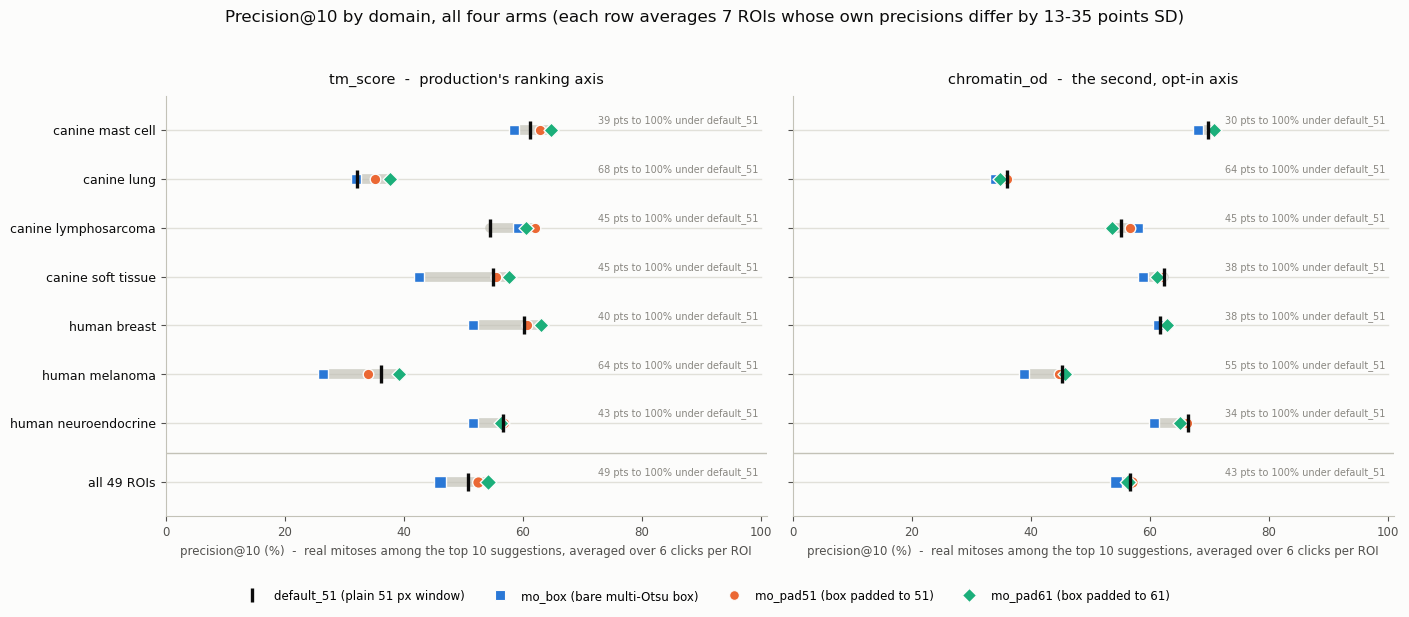

-> mopad4_domain_levels.png


In [8]:
def recessive(ax):
    """
        Push an axes' frame and ticks behind the data, the house style for every panel here.

        ax (matplotlib.axes.Axes): the axes to restyle.

        Returns None.
    """
    ax.set_facecolor(SURFACE)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(AXIS_LINE)
    ax.tick_params(colors=SECONDARY, labelsize=8.5)


ROWS = DOMAIN_ORDER + [POOLED]
YPOS = {dom: 1.2 + (len(DOMAIN_ORDER) - 1 - i) for i, dom in enumerate(DOMAIN_ORDER)}   # first domain at the top
YPOS[POOLED] = 0.0                                                                       # the pooled row sits below a divider, like a table total
DIVIDER = 0.6
YTICKS, YLABELS = [YPOS[r] for r in ROWS], [SHORT[r] for r in ROWS]


def arm_handles(size=7):
    """
        Legend handles for the four arms, marker and colour matching every figure.

        size (float): the marker size in points.

        Returns list[matplotlib.lines.Line2D]: one handle per arm, in ARMS order.
    """
    return [mlines.Line2D([], [], color=ARM_COLOR[a], marker=ARM_MARKER[a], linestyle='none', markersize=size + (3 if a == 'default_51' else 0), markeredgewidth=2.4 if a == 'default_51' else 0.8, markeredgecolor=ARM_COLOR[a] if a == 'default_51' else SURFACE, label=ARM_LABEL[a]) for a in ARMS]


def plot_arm_point(ax, x, y, arm, size=60):
    """
        Draw one arm's marker, with the reference arm as a tall ink tick and the others as filled shapes.

        ax (matplotlib.axes.Axes): the axes to draw on.
        x (float): the marker's x.
        y (float): the marker's y.
        arm (str): the arm, which sets colour and shape.
        size (float): the scatter size.

        Returns None.
    """
    if arm == 'default_51':
        ax.scatter([x], [y], marker='|', s=size * 2.6, color=INK, linewidths=2.4, zorder=5)
    else:
        ax.scatter([x], [y], marker=ARM_MARKER[arm], s=size, color=ARM_COLOR[arm], edgecolors=SURFACE, linewidths=1.0, zorder=4)


fig, axes = plt.subplots(1, 2, figsize=(14.2, 5.8), sharey=True, facecolor=SURFACE)
for ax, axis in zip(axes, AXES):
    recessive(ax)
    tab = PREC_PCT[axis]
    for row in ROWS:
        y, vals = YPOS[row], tab.loc[row, list(ARMS)]
        ax.plot([0, 100], [y, y], color=GRID, linewidth=1, zorder=1)
        ax.plot([vals.min(), vals.max()], [y, y], color=AXIS_LINE, linewidth=7, solid_capstyle='round', alpha=0.7, zorder=2)
        for arm in ARMS:
            plot_arm_point(ax, vals[arm], y, arm, size=70 if row == POOLED else 58)
        ax.annotate(f"{100 - vals['default_51']:.0f} pts to 100% under default_51", (100, y), xytext=(-2, 5), textcoords='offset points', ha='right', fontsize=7, color=MUTED)
    ax.axhline(DIVIDER, color=AXIS_LINE, linewidth=1, zorder=1)
    ax.set_xlim(0, 101)
    ax.set_title(AXIS_TITLE[axis], fontsize=10.5, color=INK, pad=9)
    ax.set_xlabel('precision@10 (%)  -  real mitoses among the top 10 suggestions, averaged over 6 clicks per ROI', fontsize=8.5, color=SECONDARY)
axes[0].set_yticks(YTICKS)
axes[0].set_yticklabels(YLABELS, fontsize=9, color=INK)
axes[0].set_ylim(-0.7, max(YTICKS) + 0.7)
fig.legend(handles=arm_handles(), loc='lower center', ncol=4, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, -0.05))
fig.suptitle('Precision@10 by domain, all four arms (each row averages 7 ROIs whose own precisions differ by 13-35 points SD)', fontsize=12, color=INK, y=0.99)
fig.tight_layout(rect=[0, 0.02, 1, 0.96])
fig.savefig(FIG['levels'], dpi=150, bbox_inches='tight', facecolor=SURFACE)
plt.show()
print(f"-> {FIG['levels']}")

## Figure 2: gains and losses, domain by domain

One cell per (domain, contrast), in points of precision@10. Blue is a gain for the first-named arm, red a loss, and
gray about zero. Under each value are W/L/T over the domain's 7 ROIs. The columns fall into three groups:

- **each arm against `default_51`**, the plain window: what swapping the template does, relative to where we
  started;
- **each pad against the bare box**: what the padding adds. These are the parent's two tested contrasts, and they
  are pooled-significant at `tm_score`;
- **pad 61 against pad 51**: what widening the pad adds.

`mo_box - default_51` changes three things at once: the kept region, the centre (box centre instead of click) and
the template size. It is therefore not "tightening" alone.

Both panels share one colour scale, so equal colours mean equal points.

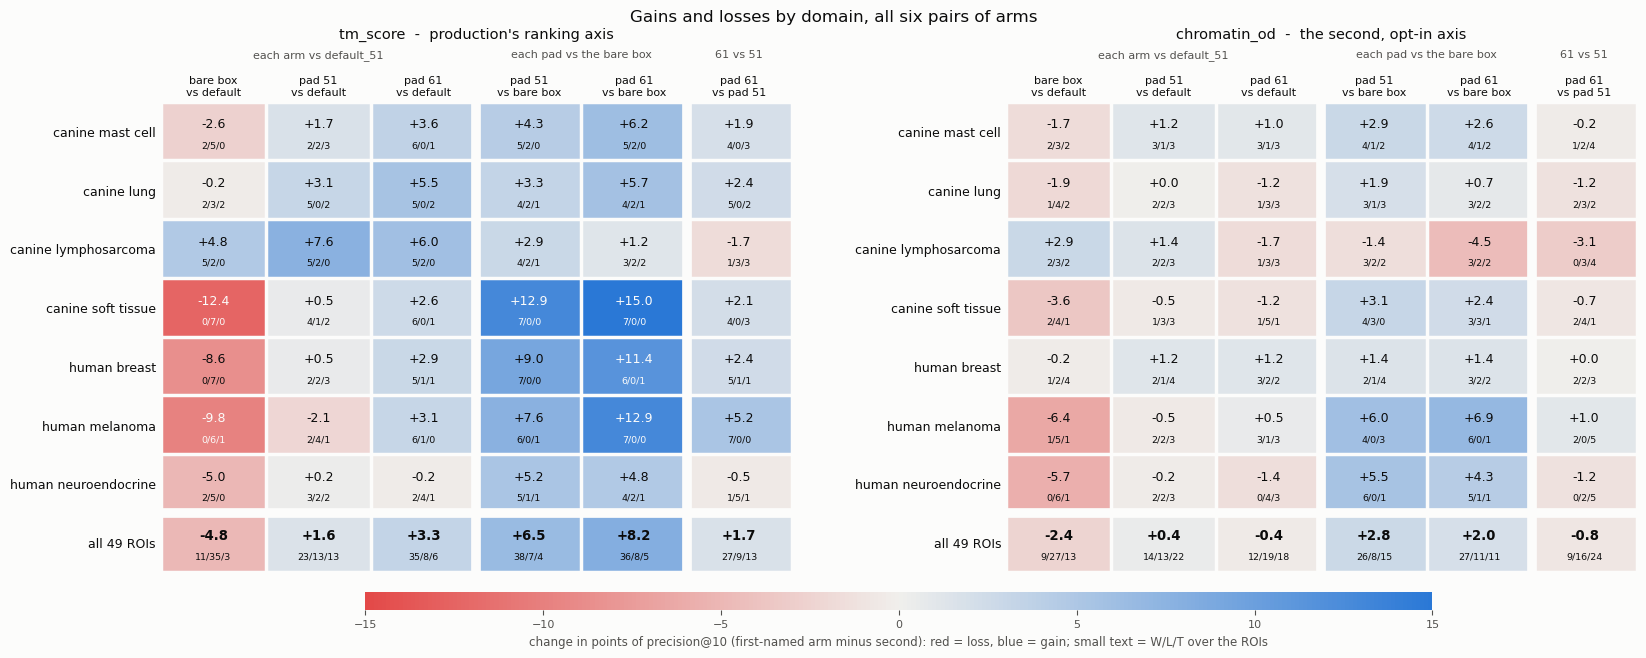

-> mopad4_domain_gain_heatmap.png


In [9]:
MAT = {axis: DSTATS[DSTATS['rank_key'] == axis].pivot(index='domain', columns='contrast', values='pooled_delta_precision').loc[ROWS, list(CONTRASTS)] * 100 for axis in AXES}
WLT = {axis: DSTATS[DSTATS['rank_key'] == axis].assign(w=lambda x: [f'{r.wins}/{r.losses}/{r.ties}' for r in x.itertuples()]).pivot(index='domain', columns='contrast', values='w').loc[ROWS, list(CONTRASTS)] for axis in AXES}
VMAX = math.ceil(max(MAT[a].abs().to_numpy().max() for a in AXES))
norm = TwoSlopeNorm(vcenter=0, vmin=-VMAX, vmax=VMAX)

fig, axes = plt.subplots(1, 2, figsize=(16.4, 6.6), facecolor=SURFACE)
fig.subplots_adjust(left=0.09, right=0.99, wspace=0.34)
for ax, axis in zip(axes, AXES):
    m = MAT[axis].to_numpy()
    im = ax.imshow(m, cmap=DIVERGING, norm=norm, aspect='auto')
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m[i, j]
            ink = SURFACE if abs(v) > 0.62 * VMAX else INK
            ax.text(j, i - 0.12, f'{v:+.1f}', ha='center', va='center', fontsize=9.5 if ROWS[i] == POOLED else 9, fontweight='bold' if ROWS[i] == POOLED else 'normal', color=ink)
            ax.text(j, i + 0.24, WLT[axis].iat[i, j], ha='center', va='center', fontsize=6.8, color=ink)
    ax.set_xticks(range(len(CONTRASTS)))
    ax.set_xticklabels([CONTRAST_LABEL[c] for c in CONTRASTS], fontsize=8, color=INK)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(ROWS)))
    ax.set_yticklabels(YLABELS, fontsize=9, color=INK)
    ax.set_xticks(np.arange(-0.5, len(CONTRASTS)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(ROWS)), minor=True)
    ax.grid(which='minor', color=SURFACE, linewidth=2.5)
    ax.tick_params(which='both', length=0)
    for x in (2.5, 4.5):
        ax.axvline(x, color=SURFACE, linewidth=7)
    ax.axhline(len(DOMAIN_ORDER) - 0.5, color=SURFACE, linewidth=7)
    for s in ax.spines.values():
        s.set_visible(False)
    for x0, x1, label in ((0, 2, 'each arm vs default_51'), (3, 4, 'each pad vs the bare box'), (5, 5, '61 vs 51')):
        ax.annotate(label, ((x0 + x1) / 2, -1.25), xycoords='data', ha='center', fontsize=8, color=SECONDARY, annotation_clip=False)
    ax.set_title(AXIS_TITLE[axis], fontsize=10.5, color=INK, pad=46)
cbar = fig.colorbar(im, ax=axes, orientation='horizontal', fraction=0.035, pad=0.04, aspect=60)
cbar.set_label('change in points of precision@10 (first-named arm minus second): red = loss, blue = gain; small text = W/L/T over the ROIs', fontsize=8.5, color=SECONDARY)
cbar.ax.tick_params(colors=SECONDARY, labelsize=8)
cbar.outline.set_visible(False)
fig.suptitle('Gains and losses by domain, all six pairs of arms', fontsize=12, color=INK, y=1.02)
fig.savefig(FIG['heatmap'], dpi=150, bbox_inches='tight', facecolor=SURFACE)
plt.show()
print(f"-> {FIG['heatmap']}")

## Figure 3: the ROIs under each domain's number

Figure 2 gives one number per domain. This figure puts the 7 ROIs under it, for the three arms measured against
`default_51`. Each gray dot is one ROI (6 clicks); one TP on one ROI is 1.67 points. The ink dot is the domain's
change and the ink bar is its t interval over the 7 ROIs, which is spread, not a test. The pooled row uses the same
t interval over all 49 ROIs. Every panel shares one x-axis.

A domain whose dots straddle zero with one far-out ROI is a different thing from a domain whose dots all sit on
one side, even when the two have the same mean.

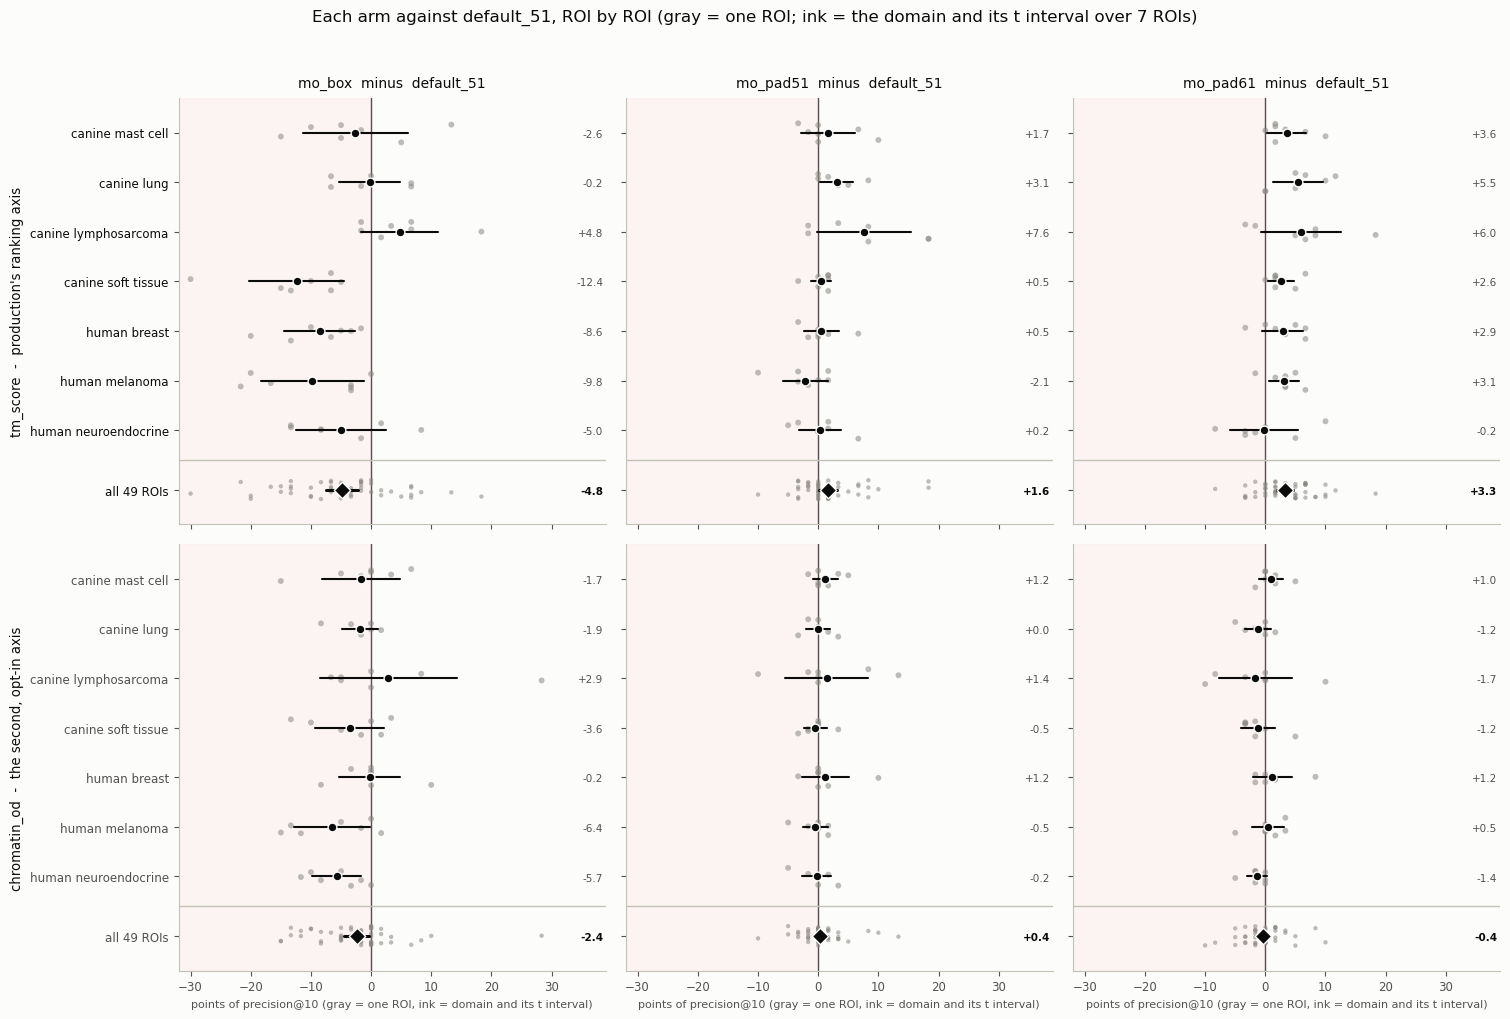

-> mopad4_domain_roi_forest.png


In [10]:
all_pts = np.concatenate([DELTAS[(a, c)].to_numpy() * PTS_PER_TP_ROI for a in AXES for c in VS_DEFAULT])
XLIM = (math.floor(all_pts.min() / 5) * 5 - 2, math.ceil(all_pts.max() / 5) * 5 + 9)
jitter = np.random.default_rng(7)

fig, axes = plt.subplots(2, 3, figsize=(15.2, 10.2), sharey=True, sharex=True, facecolor=SURFACE)
for r, axis in enumerate(AXES):
    for cix, c in enumerate(VS_DEFAULT):
        ax = axes[r, cix]
        recessive(ax)
        ax.axvspan(XLIM[0], 0, color=RED, alpha=0.04, zorder=0)
        ax.axvline(0, color=SECONDARY, linewidth=1, zorder=1)
        ax.axhline(DIVIDER, color=AXIS_LINE, linewidth=1, zorder=1)
        stats = DSTATS[(DSTATS['rank_key'] == axis) & (DSTATS['contrast'] == c)].set_index('domain')
        for row in ROWS:
            y = YPOS[row]
            files = ROI_ORDER if row == POOLED else DOMAIN_FILES[row]
            pts = DELTAS[(axis, c)].loc[files].to_numpy() * PTS_PER_TP_ROI
            ax.scatter(pts, y + jitter.uniform(-0.2, 0.2, len(pts)), s=10 if row == POOLED else 18, color=MUTED, alpha=0.55, edgecolors='none', zorder=2)
            st = stats.loc[row]
            v, lo, hi = 100 * st['pooled_delta_precision'], 100 * st['t_ci_low'], 100 * st['t_ci_high']
            ax.plot([lo, hi], [y, y], color=INK, linewidth=2.2 if row == POOLED else 1.5, solid_capstyle='round', zorder=3)
            ax.scatter([v], [y], s=70 if row == POOLED else 40, marker='D' if row == POOLED else 'o', color=INK, edgecolors=SURFACE, linewidths=1.0, zorder=4)
            ax.annotate(f'{v:+.1f}', (XLIM[1], y), xytext=(-2, -3), textcoords='offset points', ha='right', fontsize=7.5, color=INK if row == POOLED else SECONDARY, fontweight='bold' if row == POOLED else 'normal')
        ax.set_xlim(*XLIM)
        if r == 0:
            ax.set_title(c.replace(' - ', '  minus  '), fontsize=10, color=INK, pad=8)
        if r == 1:
            ax.set_xlabel('points of precision@10 (gray = one ROI, ink = domain and its t interval)', fontsize=8, color=SECONDARY)
    axes[r, 0].set_ylabel(AXIS_TITLE[axis], fontsize=9.5, color=INK)
axes[0, 0].set_yticks(YTICKS)
axes[0, 0].set_yticklabels(YLABELS, fontsize=8.5, color=INK)
axes[0, 0].set_ylim(-0.7, max(YTICKS) + 0.7)
fig.suptitle('Each arm against default_51, ROI by ROI (gray = one ROI; ink = the domain and its t interval over 7 ROIs)', fontsize=12, color=INK, y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.975])
fig.savefig(FIG['forest'], dpi=150, bbox_inches='tight', facecolor=SURFACE)
plt.show()
print(f"-> {FIG['forest']}")

## Where each domain stands: the ceiling, and how many mitoses the ROI offers

The first cell below prints the ceiling arithmetic. It then prints **every** ROI-level correlate computed while this
notebook was being designed, all of them **post hoc**, so that none is picked out because it looked best. All 49
ROIs cover about 2 mm^2, so the count of other mitoses and mitotic density are the same variable.

It then fits, **for each arm and axis separately**, one logistic curve across all 49 ROIs:
`TP out of 60 ~ log(other mitoses)`. A ROI's **residual** is its precision minus the curve's value at its mitosis
count, in points. A domain's mean residual answers a narrower question than its raw level: is the domain low only
because its ROIs have few mitoses, or is it low even at its mitosis count? The fit and its residuals are descriptive.

In [11]:
print(f"ceiling: the fewest other mitoses in any ROI is {ROI_META['n_gt_mitotic'].min()} ({ROI_META['n_gt_mitotic'].idxmin()}), which is >= {TEST_K}, so every click could reach {TEST_K}/{TEST_K}: headroom is measured against 100%")
print(f"ROI area: {ROI_META['area_mm2'].min():.3f}-{ROI_META['area_mm2'].max():.3f} mm^2, so the mitosis count and mitotic density rank the ROIs almost identically "
      f"(Spearman {sps.spearmanr(ROI_META['n_gt_mitotic'], ROI_META['n_gt_mitotic'] / ROI_META['area_mm2'])[0]:+.3f})\n")

ROI_LEVEL = pd.DataFrame({(axis, arm): [ROI_TP[(axis, arm, f)] for f in ROI_ORDER] for axis in AXES for arm in ARMS}, index=ROI_ORDER)
covars = {'other mitoses': ROI_META['n_gt_mitotic'], 'labelled look-alikes': ROI_META['n_lookalikes_db'], 'mitosis share of labelled figures': ROI_META['n_mitoses_db'] / (ROI_META['n_mitoses_db'] + ROI_META['n_lookalikes_db']), 'ROI area (mm^2)': ROI_META['area_mm2']}
grid = pd.DataFrame({f'{axis} | {arm}': {k: '{:+.2f} ({:.1g})'.format(*sps.spearmanr(v.to_numpy(), ROI_LEVEL[(axis, arm)].to_numpy())) for k, v in covars.items()} for axis in AXES for arm in ARMS})
print('POST HOC -- every per-ROI correlate looked at while designing this notebook. Spearman rho of ROI precision@10 with each (p in brackets):')
print(grid.to_string(), '\n')

X_LOG = np.log(ROI_META['n_gt_mitotic'].to_numpy().astype(float))
FITS, RESID = {}, {}
for axis in AXES:
    for arm in ARMS:
        tp = ROI_LEVEL[(axis, arm)].to_numpy()
        n = N_CLICKS_PER_ROI * TEST_K
        fit = sm.GLM(np.column_stack([tp, n - tp]), sm.add_constant(X_LOG), family=sm.families.Binomial()).fit()
        FITS[(axis, arm)] = fit.params
        RESID[(axis, arm)] = pd.Series(100 * (tp / n - fit.predict(sm.add_constant(X_LOG))), index=ROI_ORDER)


def fitted_curve(axis, arm, counts):
    """
        The pooled logistic fit's precision@10 (%) at given mitosis counts.

        axis (str): the ranking axis.
        arm (str): the arm whose fit to use.
        counts (np.ndarray): counts of other mitoses in the ROI.

        Returns np.ndarray: fitted precision@10 in percent.
    """
    b0, b1 = FITS[(axis, arm)]
    return 100 / (1 + np.exp(-(b0 + b1 * np.log(counts))))


for axis in AXES:
    t = pd.DataFrame({arm: RESID[(axis, arm)].groupby(ROI_META['domain']).mean() for arm in ARMS}).loc[DOMAIN_ORDER]
    t['median other mitoses'] = ROI_META.groupby('domain')['n_gt_mitotic'].median().loc[DOMAIN_ORDER]
    t['raw default_51'] = PREC_PCT[axis].loc[DOMAIN_ORDER, 'default_51']
    res0 = RESID[(axis, 'default_51')]
    t['default_51: ROIs below curve'] = [int((res0.loc[DOMAIN_FILES[d]] < 0).sum()) for d in DOMAIN_ORDER]
    t['default_51: without its lowest ROI'] = [res0.loc[DOMAIN_FILES[d]].drop(res0.loc[DOMAIN_FILES[d]].idxmin()).mean() for d in DOMAIN_ORDER]
    t['lowest ROI'] = [f"{res0.loc[DOMAIN_FILES[d]].idxmin()} ({res0.loc[DOMAIN_FILES[d]].min():+.0f})" for d in DOMAIN_ORDER]
    print(f'{axis}: mean residual against the pooled mitosis-count curve (points; + = above what its mitosis count predicts), per arm; then how many of')
    print("  the domain's 7 ROIs sit below the default_51 curve, and its default_51 mean residual with its single lowest ROI dropped")
    print(t.rename(index=SHORT).round(2).to_string())
    print('  fitted precision@10 at 15 / 30 / 60 / 120 other mitoses, default_51: ' + ' / '.join(f'{v:.1f}' for v in fitted_curve(axis, 'default_51', np.array([15, 30, 60, 120]))) + '\n')

lvl = pd.concat({f'{axis}|{arm}': ROI_LEVEL[(axis, arm)] * PTS_PER_TP_ROI for axis in AXES for arm in ARMS}, axis=1)
lvl.insert(0, 'domain', ROI_META['domain'].map(SHORT))
lvl.insert(1, 'other_mitoses', ROI_META['n_gt_mitotic'])
for axis in AXES:
    arms_cols = [f'{axis}|{arm}' for arm in ARMS]
    lvl[f'{axis}|min_over_arms'] = lvl[arms_cols].min(axis=1)
    lvl[f'{axis}|max_over_arms'] = lvl[arms_cols].max(axis=1)
for axis in AXES:
    s = lvl.sort_values(f'{axis}|min_over_arms')
    cols = ['domain', 'other_mitoses'] + [f'{axis}|{arm}' for arm in ARMS]
    print(f'{axis}: the 6 lowest ROIs (by their worst arm) and the 6 highest (by their worst arm), precision@10 %:')
    print(pd.concat([s.head(6), s.tail(6)])[cols].round(1).to_string(), '\n')
roi_out = lvl.copy()
for axis in AXES:
    for arm in ARMS:
        roi_out[f'{axis}|{arm}|resid_pts'] = RESID[(axis, arm)]
roi_out = roi_out.join(ROI_META[['n_mitoses_db', 'n_lookalikes_db', 'area_mm2']])
roi_out.to_csv(OUT['roi_levels'], index_label='file_name')
print(f"-> {OUT['roi_levels']}")

ceiling: the fewest other mitoses in any ROI is 14 (339.tiff), which is >= 10, so every click could reach 10/10: headroom is measured against 100%
ROI area: 1.988-2.020 mm^2, so the mitosis count and mitotic density rank the ROIs almost identically (Spearman +0.999)

POST HOC -- every per-ROI correlate looked at while designing this notebook. Spearman rho of ROI precision@10 with each (p in brackets):


                                  tm_score | default_51 tm_score | mo_box tm_score | mo_pad51 tm_score | mo_pad61 chromatin_od | default_51 chromatin_od | mo_box chromatin_od | mo_pad51 chromatin_od | mo_pad61
other mitoses                             +0.59 (8e-06)     +0.63 (1e-06)       +0.64 (9e-07)       +0.62 (2e-06)            +0.46 (0.0008)        +0.50 (0.0003)          +0.49 (0.0004)          +0.47 (0.0006)
labelled look-alikes                      +0.38 (0.006)     +0.44 (0.002)       +0.43 (0.002)       +0.40 (0.004)               +0.24 (0.1)          +0.27 (0.06)            +0.26 (0.08)             +0.24 (0.1)
mitosis share of labelled figures         +0.39 (0.006)     +0.37 (0.008)       +0.38 (0.007)       +0.39 (0.005)             +0.38 (0.007)         +0.41 (0.003)           +0.39 (0.006)           +0.38 (0.007)
ROI area (mm^2)                             -0.03 (0.8)       -0.05 (0.7)         -0.08 (0.6)         -0.10 (0.5)               +0.02 (0.9)           -0.02 (0.9

                      default_51  mo_box  mo_pad51  mo_pad61  median other mitoses  raw default_51  default_51: ROIs below curve  default_51: without its lowest ROI      lowest ROI
domain                                                                                                                                                                              
canine mast cell            7.46    9.29      7.41      7.77                  36.0           61.19                             2                               10.23   343.tiff (-9)
canine lung                -8.39   -2.75     -5.93     -5.88                  19.0           32.14                             4                               -2.99  242.tiff (-41)
canine lymphosarcoma       -8.94   -0.80     -4.21     -6.73                  89.0           54.52                             3                               -0.07  245.tiff (-62)
canine soft tissue          7.04   -0.28      6.13      6.44                  35.0           55

### Do the domains differ in level at all? (added after the first run)

A domain mean of 7 ROIs is only as precise as those ROIs agree. The first print below gives the within-domain SD of
ROI precision under `default_51`, and the standard error of each domain mean that follows from it. The test then
applies the same Kruskal-Wallis label permutation as the contrast test to the 49 per-ROI **levels**, and to their
residuals against the mitosis-count curve: 4 arms x 2 axes each, with Holm over the 4 arms within each (axis,
quantity). The permutation matrix is the one the contrast test used.

One support the first draft leaned on is weak by construction. The four arms re-measure the same 7 ROIs and the same
clicks, so a domain order that stays stable across arms is expected whether or not the domains truly differ.

In [12]:
sd = pd.DataFrame({axis: (ROI_LEVEL[(axis, 'default_51')] * PTS_PER_TP_ROI).groupby(ROI_META['domain']).std() for axis in AXES}).loc[DOMAIN_ORDER]
mean = pd.DataFrame({axis: PREC_PCT[axis].loc[DOMAIN_ORDER, 'default_51'] for axis in AXES})
print('default_51: domain mean, SD of its 7 ROI precisions, SE of the mean, and the gap to 100% in SEs (points)')
print(pd.concat({'mean': mean, 'SD over ROIs': sd, 'SE of mean': sd / math.sqrt(N_PER_DOMAIN), 'gap to 100% in SEs': (100 - mean) / (sd / math.sqrt(N_PER_DOMAIN))}, axis=1).rename(index=SHORT).round(1).to_string(), '\n')

lvl_rows = []
for axis in AXES:
    for arm in ARMS:
        for kind, v in (('level', ROI_LEVEL[(axis, arm)].to_numpy().astype(float)), ('residual vs mitosis-count curve', RESID[(axis, arm)].loc[ROI_ORDER].to_numpy())):
            h = kruskal_h_batch(v, LABELS[None, :], 7)[0]
            p = (1 + int((kruskal_h_batch(v, PERMS, 7) >= h - 1e-9).sum())) / (N_PERM + 1)
            lvl_rows.append(dict(rank_key=axis, condition=arm, quantity=kind, kruskal_h=h, perm_p=p))
LVL_HET = pd.DataFrame(lvl_rows)
LVL_HET['holm_p'] = LVL_HET.groupby(['rank_key', 'quantity'])['perm_p'].transform(lambda p: holm_adjust(p.to_numpy()))
LVL_HET.to_csv(OUT['level_heterogeneity'], index=False)
print(f"-> {OUT['level_heterogeneity']}")
print(LVL_HET.round(4).to_string(index=False), '\n')
print(f"smallest raw p over all 16 level tests: {LVL_HET['perm_p'].min():.4f}; smallest Holm p: {LVL_HET['holm_p'].min():.4f}\n")

low = pd.DataFrame({'domain': ROI_META['domain'].map(SHORT), 'other_mitoses': ROI_META['n_gt_mitotic']})
for axis in AXES:
    low[f'{axis} default_51 %'] = ROI_LEVEL[(axis, 'default_51')] * PTS_PER_TP_ROI
    low[f'{axis} resid'] = RESID[(axis, 'default_51')]
print('the 10 ROIs furthest below the default_51 tm_score curve, with their chromatin_od reading (points):')
print(low.sort_values('tm_score resid').head(10).round(1).to_string())
print('\nhow those 10 fall across domains:', low.sort_values('tm_score resid').head(10)['domain'].value_counts().to_dict())

default_51: domain mean, SD of its 7 ROI precisions, SE of the mean, and the gap to 100% in SEs (points)
                         mean              SD over ROIs              SE of mean              gap to 100% in SEs             
                     tm_score chromatin_od     tm_score chromatin_od   tm_score chromatin_od           tm_score chromatin_od
domain                                                                                                                      
canine mast cell         61.2         69.8         20.6         15.6        7.8          5.9                5.0          5.1
canine lung              32.1         36.0         23.9         24.6        9.0          9.3                7.5          6.9
canine lymphosarcoma     54.5         55.2         33.2         29.7       12.6         11.2                3.6          4.0
canine soft tissue       55.0         62.4         31.4         31.8       11.9         12.0                3.8          3.1
human breast        

-> ../results/precision_at_k_49roi_6seed_mopad_postD11_4arm_by_domain_level_heterogeneity.csv
    rank_key  condition                        quantity  kruskal_h  perm_p  holm_p
    tm_score default_51                           level     7.9004  0.2505  0.6570
    tm_score default_51 residual vs mitosis-count curve     6.0185  0.4349  0.9670
    tm_score     mo_box                           level    10.7384  0.0910  0.3640
    tm_score     mo_box residual vs mitosis-count curve     8.0015  0.2413  0.9654
    tm_score   mo_pad51                           level     8.3104  0.2190  0.6570
    tm_score   mo_pad51 residual vs mitosis-count curve     7.0531  0.3223  0.9670
    tm_score   mo_pad61                           level     6.9544  0.3332  0.6570
    tm_score   mo_pad61 residual vs mitosis-count curve     6.2942  0.4018  0.9670
chromatin_od default_51                           level     8.0376  0.2380  0.6702
chromatin_od default_51 residual vs mitosis-count curve     6.2484  0.4099  

## Figure 4: each domain's ROIs against the mitosis-count curve

One panel per domain; the last panel holds all 49 ROIs. The x-axis is the number of other mitoses in the ROI, on a
log scale. Each ROI is a hollow ink circle at its `default_51` precision and a filled aqua diamond at its `mo_pad61`
precision, joined by a thin line. The line is the change at that ROI from the plain window to the widest pad. Faint
gray dots are the other domains' ROIs (`mo_pad61`), for reference.

The two curves are the pooled fits: ink for `default_51`, aqua for `mo_pad61`. A domain whose ROIs sit below the
curves is low even for its mitosis count. A domain whose ROIs sit on the curves is low or high because of its
mitosis count.

`mo_pad61` is drawn because it is the furthest step from `default_51` among the four arms. It is not drawn because it
won; its pooled lead over `mo_pad51` was never tested. The residuals of all four arms are in the table above.

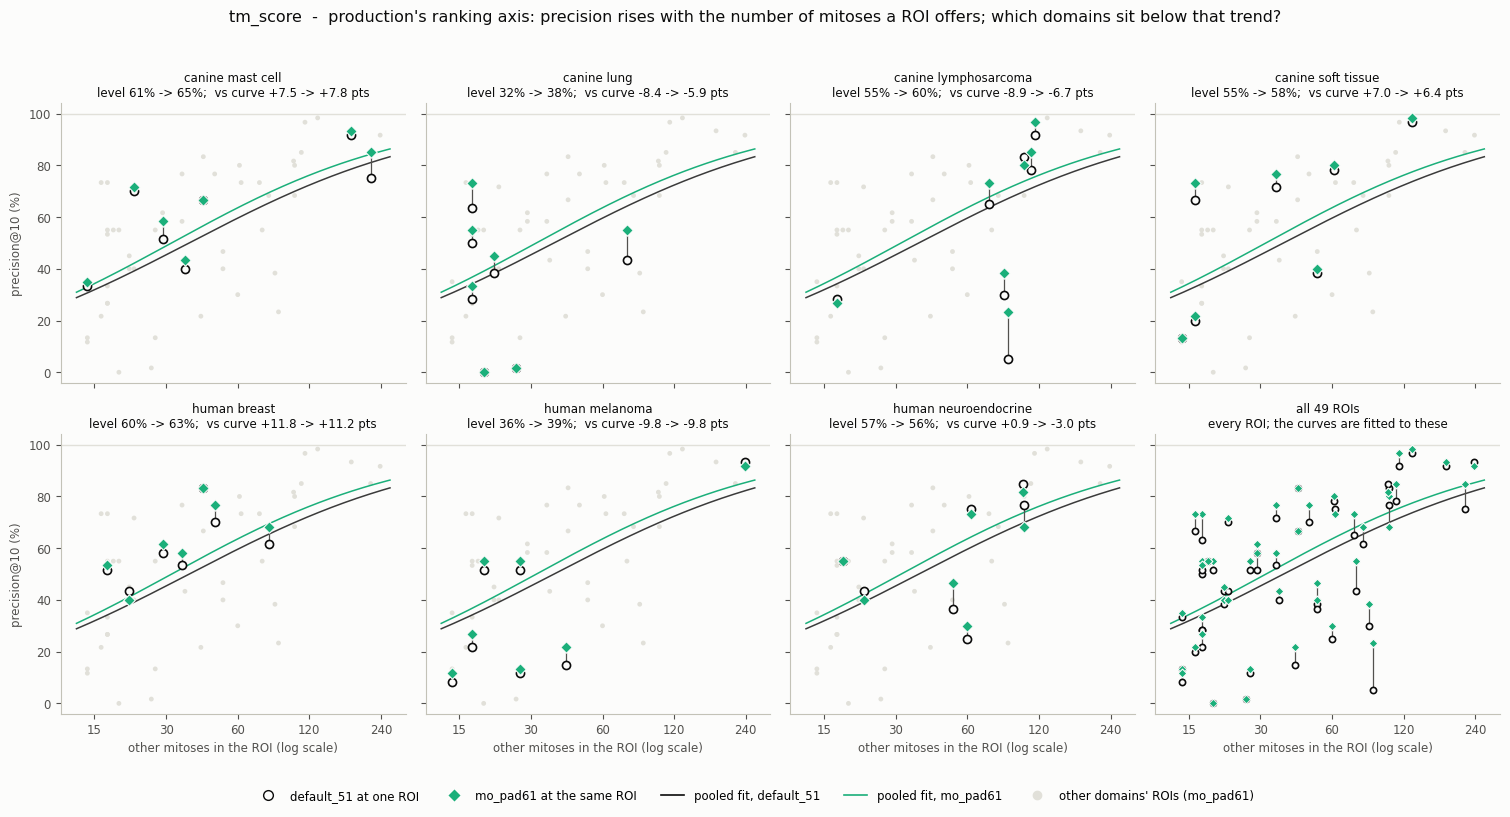

-> mopad4_domain_vs_mitosis_count_tm_score.png


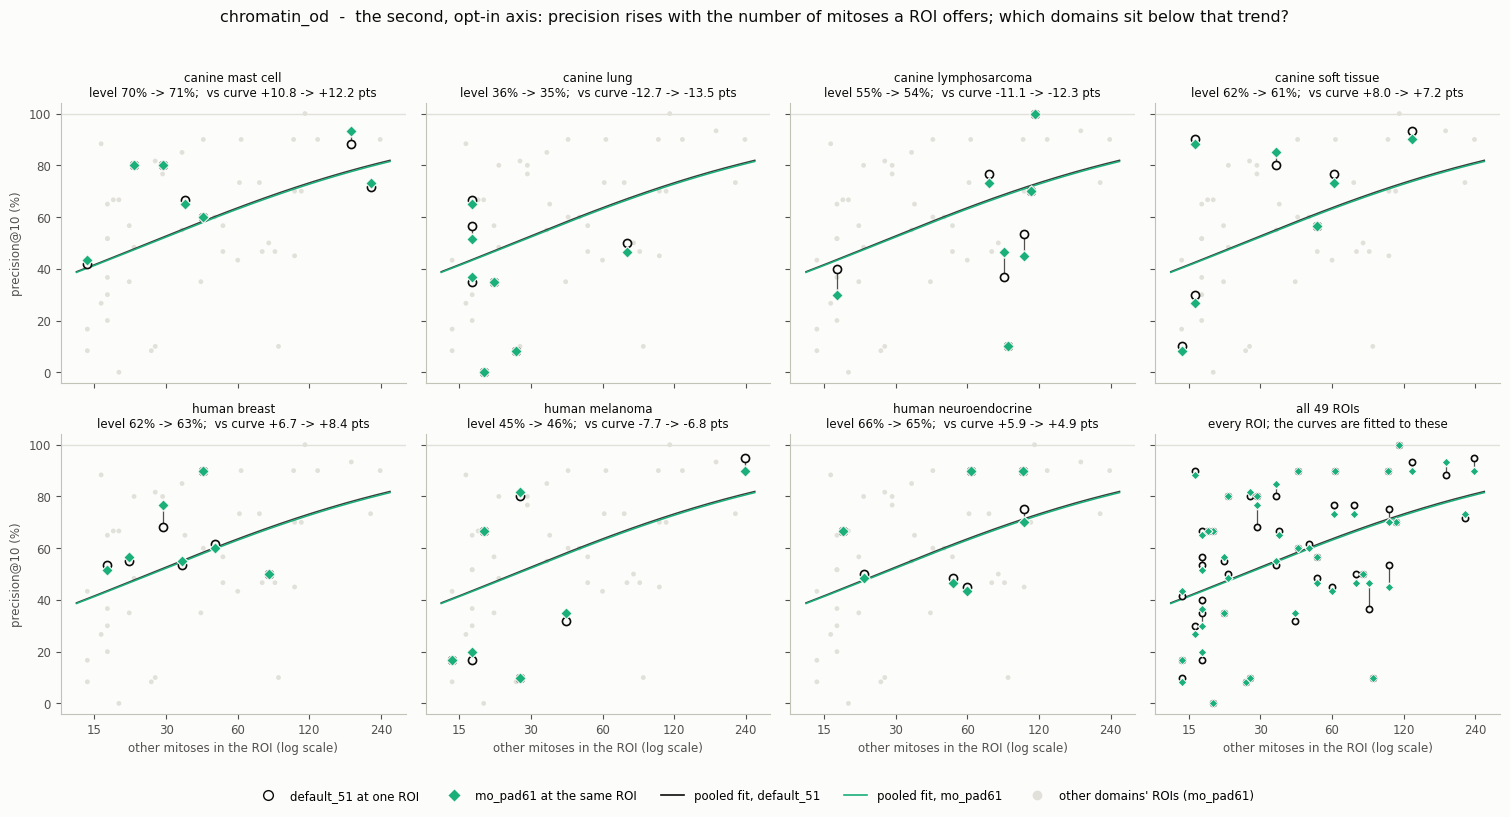

-> mopad4_domain_vs_mitosis_count_chromatin_od.png


In [13]:
X_GRID = np.geomspace(ROI_META['n_gt_mitotic'].min() * 0.9, ROI_META['n_gt_mitotic'].max() * 1.1, 200)
for axis in AXES:
    fig, axs = plt.subplots(2, 4, figsize=(15.2, 7.8), sharex=True, sharey=True, facecolor=SURFACE)
    for k, dom in enumerate(DOMAIN_ORDER + [POOLED]):
        ax = axs.flat[k]
        recessive(ax)
        ax.set_xscale('log')
        files = ROI_ORDER if dom == POOLED else DOMAIN_FILES[dom]
        others = [f for f in ROI_ORDER if f not in files]
        if others:
            ax.scatter(ROI_META.loc[others, 'n_gt_mitotic'], ROI_LEVEL.loc[others, (axis, 'mo_pad61')] * PTS_PER_TP_ROI, s=12, color=GRID, edgecolors='none', zorder=1)
        ax.plot(X_GRID, fitted_curve(axis, 'default_51', X_GRID), color=INK, linewidth=1.1, alpha=0.8, zorder=2)
        ax.plot(X_GRID, fitted_curve(axis, 'mo_pad61', X_GRID), color=AQUA, linewidth=1.1, zorder=2)
        x = ROI_META.loc[files, 'n_gt_mitotic'].to_numpy()
        y0 = ROI_LEVEL.loc[files, (axis, 'default_51')].to_numpy() * PTS_PER_TP_ROI
        y1 = ROI_LEVEL.loc[files, (axis, 'mo_pad61')].to_numpy() * PTS_PER_TP_ROI
        for xi, a, b in zip(x, y0, y1):
            ax.plot([xi, xi], [a, b], color=SECONDARY, linewidth=0.9, zorder=3)
        ax.scatter(x, y0, s=34 if dom != POOLED else 20, facecolors=SURFACE, edgecolors=INK, linewidths=1.2, zorder=4)
        ax.scatter(x, y1, s=34 if dom != POOLED else 20, marker='D', color=AQUA, edgecolors=SURFACE, linewidths=0.8, zorder=5)
        if dom != POOLED:
            r0, r1 = RESID[(axis, 'default_51')].loc[files].mean(), RESID[(axis, 'mo_pad61')].loc[files].mean()
            p0, p1 = PREC_PCT[axis].loc[dom, 'default_51'], PREC_PCT[axis].loc[dom, 'mo_pad61']
            sub = f'level {p0:.0f}% -> {p1:.0f}%;  vs curve {r0:+.1f} -> {r1:+.1f} pts'
        else:
            sub = 'every ROI; the curves are fitted to these'
        ax.set_title(f'{SHORT[dom]}\n{sub}', fontsize=8.5, color=INK, pad=5)
        ax.set_ylim(-4, 104)
        ax.axhline(100, color=GRID, linewidth=1, zorder=0)
    for ax in axs[1]:
        ax.set_xlabel('other mitoses in the ROI (log scale)', fontsize=8.5, color=SECONDARY)
    for ax in axs[:, 0]:
        ax.set_ylabel('precision@10 (%)', fontsize=8.5, color=SECONDARY)
    ticks = [15, 30, 60, 120, 240]
    for ax in axs.flat:
        ax.set_xticks(ticks)
        ax.set_xticklabels([str(t) for t in ticks])
        ax.minorticks_off()
    handles = [mlines.Line2D([], [], marker='o', linestyle='none', markerfacecolor=SURFACE, markeredgecolor=INK, markersize=7, label='default_51 at one ROI'),
               mlines.Line2D([], [], marker='D', linestyle='none', color=AQUA, markeredgecolor=SURFACE, markersize=7, label='mo_pad61 at the same ROI'),
               mlines.Line2D([], [], color=INK, linewidth=1.2, label='pooled fit, default_51'), mlines.Line2D([], [], color=AQUA, linewidth=1.2, label='pooled fit, mo_pad61'),
               mlines.Line2D([], [], marker='o', linestyle='none', color=GRID, markersize=6, label="other domains' ROIs (mo_pad61)")]
    fig.legend(handles=handles, loc='lower center', ncol=5, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, -0.035))
    fig.suptitle(f'{AXIS_TITLE[axis]}: precision rises with the number of mitoses a ROI offers; which domains sit below that trend?', fontsize=11.5, color=INK, y=0.995)
    fig.tight_layout(rect=[0, 0.02, 1, 0.975])
    fig.savefig(FIG[f'count_{axis}'], dpi=150, bbox_inches='tight', facecolor=SURFACE)
    plt.show()
    print(f"-> {FIG[f'count_{axis}']}")

## Figure 5: what fills the top-10 slots that are not mitoses

Every top-10 slot has one of three labels. It matched a **mitosis**, it matched a **labelled look-alike** (a figure
the annotators marked as not mitotic), or it had **no label within 7.5 um**. The last is not necessarily a false
positive: an unannotated real mitosis would land in it too, so this share is an upper bound on the false positives
that are truly unrelated. Each domain gets two bars, `default_51` and `mo_pad61`; the table below has all four arms.

Before anything is drawn, the cell asserts two things:

- the bucket labels map one-to-one onto the database categories;
- the mitosis count in each top 10 equals the recorded `tp_at_10` on every one of the 2,352 (click, arm, axis) lists.

buckets map 1:1 onto database categories; top-10 mitosis count == tp_at_10 on all 2352 (click, arm, axis) lists
ROIs at or below 15% precision@10 under every arm at tm_score: 5. Their default_51 top-10 composition at tm_score (slots out of 60):
           human_correct_label  human_rejected_label  non_human_findings              domain  n_gt_mitotic  n_lookalikes_db
file_name                                                                                                                  
211.tiff                     0                     0                  60         canine lung            19               18
242.tiff                     1                     0                  59         canine lung            26               37
462.tiff                     8                    12                  40  canine soft tissue            14               37
524.tiff                     5                     5                  50      human melanoma            14               13
546.tiff   

median distance (um) from a default_51 tm_score top-10 detection to the nearest annotation of either class:
  211.tiff 109, 242.tiff 76, 462.tiff 42, 524.tiff 102, 546.tiff 69   | the other 44 ROIs: median 1.3, max 115 (509.tiff)
  (matching counts a detection within 7.5 um; a median in the tens or hundreds of um means the top 10 sits away from every labelled figure)

-> ../results/precision_at_k_49roi_6seed_mopad_postD11_4arm_by_domain_top10_composition.csv

tm_score: share of top-10 slots (%) that are labelled look-alikes and that have no label nearby, per arm
                      look-alike | default_51  look-alike | mo_box  look-alike | mo_pad51  look-alike | mo_pad61  no label | default_51  no label | mo_box  no label | mo_pad51  no label | mo_pad61
domain                                                                                                                                                                                              
canine mast cell                     

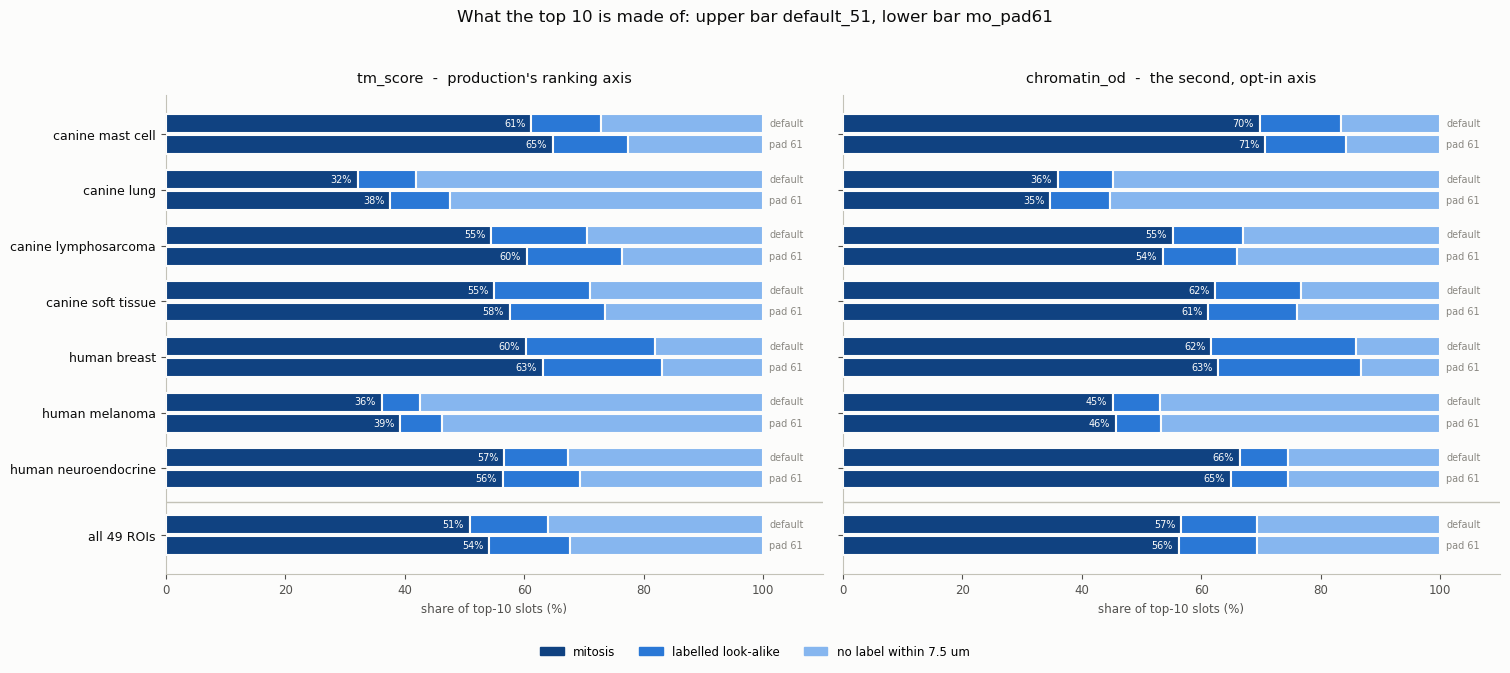

-> mopad4_domain_top10_composition.png


In [14]:
TOP = pd.concat([pd.read_csv(f'{REF}_top30.csv', float_precision='round_trip').query("condition == 'default_51'"), pd.read_csv(f'{SRC}_top30.csv', float_precision='round_trip').query('condition in @ARMS')], ignore_index=True)
TOP10 = TOP[TOP['rank'] < TEST_K].copy()
assert set(TOP['condition']) == set(ARMS) and (TOP.groupby(['file_name', 'seed_index', 'condition', 'rank_key']).size() == 30).all()
assert (TOP10.groupby(['file_name', 'seed_index', 'condition', 'rank_key']).size() == TEST_K).all(), 'a list has fewer than 10 detections'
bucket_map = TOP.groupby('bucket').agg(cats=('matched_category', lambda s: tuple(sorted(s.unique()))), unmatched=('matched_ann_id', lambda s: bool((s == -1).all())), any_unmatched=('matched_ann_id', lambda s: bool((s == -1).any())))
assert bucket_map.loc['human_correct_label', 'cats'] == (1,) and bucket_map.loc['human_rejected_label', 'cats'] == (2,) and bucket_map.loc['non_human_findings', 'cats'] == (0,)
assert bucket_map.loc['non_human_findings', 'unmatched'] and not bucket_map.loc['human_correct_label', 'any_unmatched'] and not bucket_map.loc['human_rejected_label', 'any_unmatched']
tp_from_lists = TOP10.assign(tp=TOP10['bucket'] == 'human_correct_label').groupby(['file_name', 'seed_index', 'condition', 'rank_key'])['tp'].sum()
tp_recorded = RUN.set_index(['file_name', 'seed_index', 'condition', 'rank_key'])['tp_at_10']
assert (tp_from_lists.reindex(tp_recorded.index) == tp_recorded).all(), 'a top-10 mitosis count differs from tp_at_10'
print(f'buckets map 1:1 onto database categories; top-10 mitosis count == tp_at_10 on all {len(tp_recorded)} (click, arm, axis) lists')

TOP10['domain'] = TOP10['file_name'].map(ROI_META['domain'])
comp_rows = []
for (axis, arm), g in TOP10.groupby(['rank_key', 'condition']):
    for dom in DOMAIN_ORDER + [POOLED]:
        gg = g if dom == POOLED else g[g['domain'] == dom]
        shares = gg['bucket'].value_counts(normalize=True)
        comp_rows.append(dict(rank_key=axis, condition=arm, domain=dom, n_slots=len(gg), **{b: 100 * shares.get(b, 0.0) for b in COMPOSITION}))
COMP = pd.DataFrame(comp_rows)
assert np.allclose(COMP[list(COMPOSITION)].sum(axis=1), 100)
assert np.allclose(COMP.set_index(['rank_key', 'condition', 'domain'])['human_correct_label'].to_numpy(), [PREC_PCT[a].loc[d, c] for a, c, d in COMP.set_index(['rank_key', 'condition', 'domain']).index]), 'mitosis share != precision'
COMP.to_csv(OUT['composition'], index=False)
stuck = [f for f in ROI_ORDER if all(ROI_TP[(axis, arm, f)] * PTS_PER_TP_ROI <= 15 for arm in ARMS for axis in ('tm_score',))]
print(f'ROIs at or below 15% precision@10 under every arm at tm_score: {len(stuck)}. Their default_51 top-10 composition at tm_score (slots out of 60):')
t = TOP10[(TOP10['condition'] == 'default_51') & (TOP10['rank_key'] == 'tm_score') & TOP10['file_name'].isin(stuck)].groupby(['file_name', 'bucket']).size().unstack(fill_value=0)
print(t.join(ROI_META[['domain', 'n_gt_mitotic', 'n_lookalikes_db']]).assign(domain=lambda x: x['domain'].map(SHORT)).to_string(), '\n')
ANN = pd.DataFrame(DB['annotations'])
BB = np.array(ANN['bbox'].tolist(), dtype=float)
assert (BB[:, 2] > BB[:, 0]).all() and (BB[:, 3] > BB[:, 1]).all(), 'bbox is not [x0, y0, x1, y1]'
ANN['cx'], ANN['cy'] = (BB[:, 0] + BB[:, 2]) / 2, (BB[:, 1] + BB[:, 3]) / 2
near = {}
for f in ROI_ORDER:
    xy = ANN.loc[ANN['image_id'] == ROI_META.loc[f, 'image_id'], ['cx', 'cy']].to_numpy()
    det = TOP10[(TOP10['file_name'] == f) & (TOP10['condition'] == 'default_51') & (TOP10['rank_key'] == 'tm_score')][['cx', 'cy']].to_numpy()
    near[f] = float(np.median(np.sqrt(((det[:, None, :] - xy[None, :, :]) ** 2).sum(-1)).min(axis=1)) * ROI_META.loc[f, 'mpp'])
near = pd.Series(near)
print('median distance (um) from a default_51 tm_score top-10 detection to the nearest annotation of either class:')
print('  ' + ', '.join(f'{f} {near[f]:.0f}' for f in stuck) + f"   | the other {N_ROIS - len(stuck)} ROIs: median {near.drop(stuck).median():.1f}, max {near.drop(stuck).max():.0f} ({near.drop(stuck).idxmax()})")
print('  (matching counts a detection within 7.5 um; a median in the tens or hundreds of um means the top 10 sits away from every labelled figure)\n')
print(f"-> {OUT['composition']}\n")
for axis in AXES:
    t = COMP[COMP['rank_key'] == axis].pivot(index='domain', columns='condition', values=['human_rejected_label', 'non_human_findings']).loc[DOMAIN_ORDER + [POOLED]]
    t.columns = [f"{'look-alike' if b == 'human_rejected_label' else 'no label'} | {c}" for b, c in t.columns]
    print(f'{axis}: share of top-10 slots (%) that are labelled look-alikes and that have no label nearby, per arm')
    print(t.rename(index=SHORT).round(1).to_string(), '\n')

fig, axes = plt.subplots(1, 2, figsize=(15.2, 6.4), sharey=True, facecolor=SURFACE)
BAR_ARMS = ('default_51', 'mo_pad61')
OFF = {'default_51': 0.19, 'mo_pad61': -0.19}
for ax, axis in zip(axes, AXES):
    recessive(ax)
    ax.axhline(DIVIDER, color=AXIS_LINE, linewidth=1, zorder=1)
    c = COMP[COMP['rank_key'] == axis].set_index(['domain', 'condition'])
    for row in ROWS:
        for arm in BAR_ARMS:
            y, left = YPOS[row] + OFF[arm], 0.0
            for b, (label, color) in COMPOSITION.items():
                w = c.loc[(row, arm), b]
                ax.barh(y, w, left=left, height=0.34, color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3)
                if b == 'human_correct_label':
                    ax.text(left + w - 1, y, f'{w:.0f}%', ha='right', va='center', fontsize=7, color=SURFACE, zorder=4)
                left += w
            ax.text(101, y, ARM_SHORT[arm], ha='left', va='center', fontsize=7, color=MUTED)
    ax.set_xlim(0, 110)
    ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.set_title(AXIS_TITLE[axis], fontsize=10.5, color=INK, pad=9)
    ax.set_xlabel('share of top-10 slots (%)', fontsize=8.5, color=SECONDARY)
axes[0].set_yticks(YTICKS)
axes[0].set_yticklabels(YLABELS, fontsize=9, color=INK)
axes[0].set_ylim(-0.7, max(YTICKS) + 0.7)
handles = [mpatches.Patch(color=color, label=label) for label, color in COMPOSITION.values()]
fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('What the top 10 is made of: upper bar default_51, lower bar mo_pad61', fontsize=12, color=INK, y=0.99)
fig.tight_layout(rect=[0, 0.02, 1, 0.965])
fig.savefig(FIG['composition'], dpi=150, bbox_inches='tight', facecolor=SURFACE)
plt.show()
print(f"-> {FIG['composition']}")

## Figure 6: the pooled picture, all together

**Top row.** Every domain's path through the four arms in order: plain window, bare box, box padded to 51, box
padded to 61. Thin gray lines are the domains, each labelled at its right end. The heavy ink line is all 49 ROIs
pooled.

**Bottom row.** The six pooled contrasts, each with the parent's 95% cluster-bootstrap CI over the 49 ROIs, which
this notebook reproduced bit for bit. Filled markers are the parent's two tested contrasts; hollow markers were
descriptive in the parent and stay descriptive here.

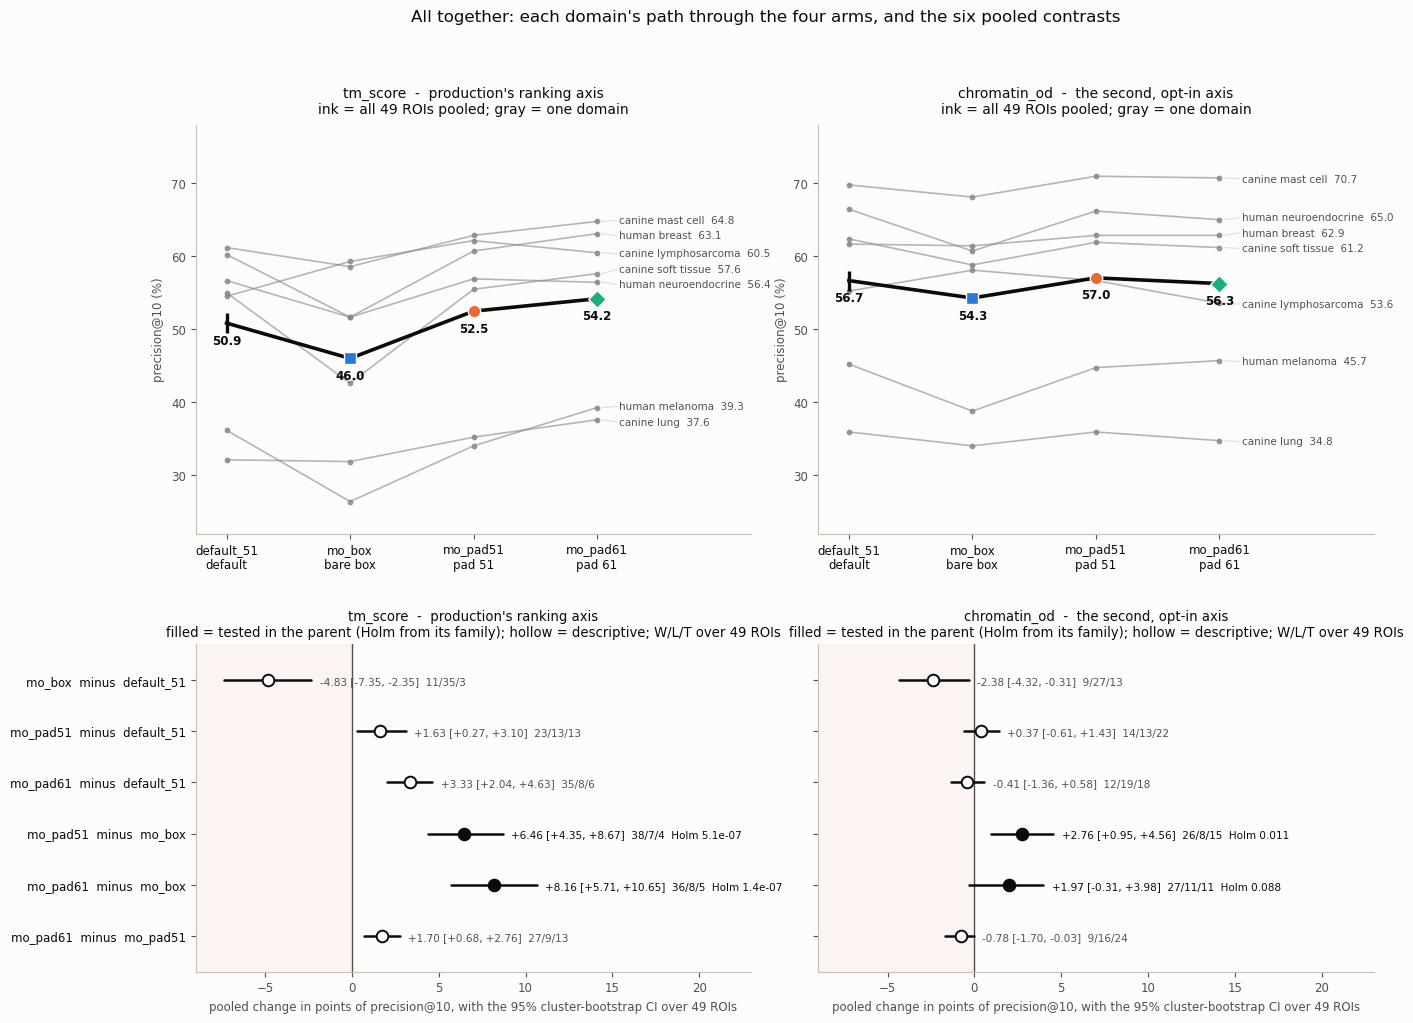

-> mopad4_pooled_overview.png


In [15]:
def spread_labels(ys, min_gap):
    """
        Nudge label positions apart so no two sit closer than min_gap, keeping their order and their mean.

        ys (array-like): the data y of each label.
        min_gap (float): the minimum spacing, in data units.

        Returns np.ndarray: the adjusted y positions, in the input order.
    """
    ys = np.asarray(ys, dtype=float)
    order = np.argsort(ys, kind='stable')
    pos = ys[order].copy()
    for i in range(1, len(pos)):
        pos[i] = max(pos[i], pos[i - 1] + min_gap)
    pos -= (pos - ys[order]).mean()
    out = np.empty_like(pos)
    out[order] = pos
    return out


fig = plt.figure(figsize=(15.2, 11.0), facecolor=SURFACE)
gs = fig.add_gridspec(2, 2, height_ratios=[1.25, 1], hspace=0.3, wspace=0.12)
XS = np.arange(len(ARMS))
lo_all = min(PREC_PCT[a].to_numpy().min() for a in AXES)
hi_all = max(PREC_PCT[a].to_numpy().max() for a in AXES)
for cix, axis in enumerate(AXES):
    ax = fig.add_subplot(gs[0, cix])
    recessive(ax)
    tab = PREC_PCT[axis]
    for dom in DOMAIN_ORDER:
        ax.plot(XS, tab.loc[dom, list(ARMS)], color=MUTED, linewidth=1.2, alpha=0.6, zorder=2)
        ax.scatter(XS, tab.loc[dom, list(ARMS)], s=10, color=MUTED, alpha=0.8, zorder=2)
    label_y = spread_labels(tab.loc[DOMAIN_ORDER, ARMS[-1]].to_numpy(), 2.1)
    for dom, ly in zip(DOMAIN_ORDER, label_y):
        ax.plot([XS[-1] + 0.04, XS[-1] + 0.16], [tab.loc[dom, ARMS[-1]], ly], color=GRID, linewidth=0.8)
        ax.text(XS[-1] + 0.18, ly, f'{SHORT[dom]}  {tab.loc[dom, ARMS[-1]]:.1f}', va='center', fontsize=7.5, color=SECONDARY)
    ax.plot(XS, tab.loc[POOLED, list(ARMS)], color=INK, linewidth=2.6, zorder=4)
    for x, arm in zip(XS, ARMS):
        v = tab.loc[POOLED, arm]
        plot_arm_point(ax, x, v, arm, size=80)
        ax.annotate(f'{v:.1f}', (x, v), xytext=(0, -15), textcoords='offset points', ha='center', fontsize=8.5, color=INK, fontweight='bold')
    ax.set_xticks(XS)
    ax.set_xticklabels([f'{a}\n{ARM_SHORT[a]}' for a in ARMS], fontsize=8.5, color=INK)
    ax.set_xlim(-0.25, XS[-1] + 1.25)
    ax.set_ylim(math.floor(lo_all / 5) * 5 - 3, math.ceil(hi_all / 5) * 5 + 3)
    ax.set_ylabel('precision@10 (%)', fontsize=8.5, color=SECONDARY)
    ax.set_title(f'{AXIS_TITLE[axis]}\nink = all 49 ROIs pooled; gray = one domain', fontsize=10, color=INK, pad=8)

CON_Y = {c: len(CONTRASTS) - 1 - i for i, c in enumerate(CONTRASTS)}
lo_ci = min(100 * POOLED_STATS[(a, c)]['ci_low'] for a in AXES for c in CONTRASTS)
hi_ci = max(100 * POOLED_STATS[(a, c)]['ci_high'] for a in AXES for c in CONTRASTS)
for cix, axis in enumerate(AXES):
    ax = fig.add_subplot(gs[1, cix])
    recessive(ax)
    ax.axvspan(-100, 0, color=RED, alpha=0.04, zorder=0)
    ax.axvline(0, color=SECONDARY, linewidth=1, zorder=1)
    for c in CONTRASTS:
        st, y = POOLED_STATS[(axis, c)], CON_Y[c]
        v, lo, hi = 100 * st['pooled_delta_precision'], 100 * st['ci_low'], 100 * st['ci_high']
        tested = c in PARENT_TESTED
        ax.plot([lo, hi], [y, y], color=INK, linewidth=1.8, solid_capstyle='round', zorder=3)
        ax.scatter([v], [y], s=70, color=INK if tested else SURFACE, edgecolors=INK, linewidths=1.4, zorder=4)
        note = f"{v:+.2f} [{lo:+.2f}, {hi:+.2f}]  {st['wins']}/{st['losses']}/{st['ties']}"
        note += f"  Holm {st['parent_holm_p']:.2g}" if tested else ''
        ax.annotate(note, (hi, y), xytext=(6, -3), textcoords='offset points', fontsize=7.5, color=INK if tested else SECONDARY)
    ax.set_yticks(list(CON_Y.values()))
    ax.set_yticklabels([c.replace(' - ', '  minus  ') for c in CON_Y] if cix == 0 else [], fontsize=8.5, color=INK)
    ax.set_xlim(math.floor(lo_ci) - 1, math.ceil(hi_ci) + 12)
    ax.set_title(f"{AXIS_TITLE[axis]}\nfilled = tested in the parent (Holm from its family); hollow = descriptive; W/L/T over 49 ROIs", fontsize=9.5, color=INK, pad=6)
    ax.set_ylim(-0.7, len(CONTRASTS) - 0.3)
    ax.set_xlabel('pooled change in points of precision@10, with the 95% cluster-bootstrap CI over 49 ROIs', fontsize=8.5, color=SECONDARY)
fig.suptitle("All together: each domain's path through the four arms, and the six pooled contrasts", fontsize=12, color=INK, y=0.985)
fig.savefig(FIG['pooled'], dpi=150, bbox_inches='tight', facecolor=SURFACE)
plt.show()
print(f"-> {FIG['pooled']}")

## Reading the result

Every number below is printed by a cell above. "Points" are percentage points of precision@10, and only K = 10 is
used.

**Every gate held.**
- The 12 pooled `delta_stats` rows and all 588 per-ROI deltas reproduce the parent.
- The pooled precisions match the published values.
- `default_51` is identical in both source runs.
- The mitosis count in every top 10 equals `tp_at_10` on all 2,352 lists.

### 1. The domains do not differ in level beyond ROI-to-ROI variation

- **The domain means look far apart.** At `tm_score` they span 27-33 points for each arm, against at most 15.0
  points between the arms within a domain.
- **But the 7 ROIs inside a domain vary even more.** Their SD under `default_51` runs from **13 to 33 points**
  (breast lowest, lymphosarcoma highest). A domain mean is therefore uncertain by 5-13 points (one SE).
- **The label-permutation test finds no domain difference in level:** 4 arms x 2 axes, smallest raw p 0.091, smallest
  Holm p 0.36.
- **Adjusting for mitosis count does not change that.** The residuals against the mitosis-count curve show no domain
  difference either (raw p 0.20-0.43).

So **these 49 ROIs do not establish that any tumour type is easier or harder than another.** Canine lung and human
melanoma have the lowest means under every arm on both axes. That order would look stable across arms either way,
because the four arms re-measure the same ROIs.

**Changes can be established even though levels cannot,** because every template comparison is paired within the
ROI. Pairing cancels the ROI-to-ROI variation that swamps the levels.

### 2. How the gains and losses change across domains (Figures 2-3)

**No single domain's number is a finding.** With 7 ROIs, a domain cannot reach a Holm-corrected p below 0.109. Seven
rows hit exactly that floor, with every ROI moving the same way, for example soft tissue at 0/7/0 for the bare box and
melanoma at 7/0/0 for 61 vs 51. They are still not significant. What *can* be tested is whether the change differs
between domains, using all 49 ROIs. At `tm_score`, two of the six contrasts pass:

- **The bare box's loss against `default_51` depends on the domain.** Permutation p = 0.0015, Holm 0.009. It still
  holds when any single ROI is dropped: the worst-case Holm is 0.035.
  - The change is negative in 6 of 7 domains: soft tissue **-12.4** (0/7/0), melanoma **-9.8** (0/6/1), breast
    **-8.6** (0/7/0), neuroendocrine -5.0, mast cell -2.6, and lung -0.2, which is essentially flat.
  - Canine lymphosarcoma moves the other way, **+4.8** (5/2/0).
- **Widening the pad from 51 to 61 helps in some domains and not in others.** Permutation p = 0.0028, Holm 0.014,
  worst-case leave-one-out Holm 0.040.
  - Melanoma gains **+5.2** (7/0/0).
  - Mast cell, lung, soft tissue and breast gain **+1.9 to +2.4**.
  - Lymphosarcoma (**-1.7**, 1/3/3) and neuroendocrine (**-0.5**, 1/5/1) do not gain.

Which domains sit where inside those two contrasts is descriptive. The other four contrasts show no domain difference
that survives Holm.

- **Both pads beat the bare box in every domain at `tm_score`.** `mo_pad51 - mo_box` runs from +2.9 to +12.9 and
  `mo_pad61 - mo_box` from +1.2 to +15.0, largest where the bare box lost most (soft tissue, breast, melanoma). A
  domain difference is not established (Holm 0.43 and 0.25). At `chromatin_od` the same contrasts are negative in
  lymphosarcoma (-1.4 and -4.5).
- **The net gain of `mo_pad61` over the plain window is broad at `tm_score`.** It is positive in 6 of 7 domains, from
  +2.6 to +6.0. Neuroendocrine is the exception at -0.2 (2/4/1), which means no detectable change, not a loss. No
  domain difference is detected (Holm 0.43). `mo_pad51 - default_51` runs from -2.1 (melanoma) to +7.6
  (lymphosarcoma), also with no domain difference detected (Holm 0.29).

**At `chromatin_od`, no contrast differs between domains.** Every Holm p is 1.0, and the smallest raw p is 0.20. Both
pads stay within +/-1.7 points of `default_51` in every domain.

**Fragile domain readings,** from the leave-one-ROI-out table:
- lymphosarcoma's `mo_pad51 - mo_box` at `tm_score` (+2.9) falls to 0.0 without `291.tiff`;
- at `chromatin_od`, `293.tiff` alone carries lymphosarcoma's bare-box +2.9 (it is -1.4 without it) and its
  `mo_pad61 - mo_box` of -4.5 (+0.8 without it).

Soft tissue's pad gains hold up: dropping any one ROI leaves +9.7 to +14.2.

**Post hoc, and not an explanation.** At the domain level, the two domain-dependent contrasts track the median box
side: rho -0.80 for bare box minus default, +0.72 for 61 vs 51. Smaller boxes lose less without a pad; bigger boxes
gain more from the wider pad. But the ROI-level correlations are weak (-0.30 and +0.32). Canine ROIs also have
smaller boxes (22/28 below the overall median, against 16/21 human ROIs above it), so box size and species cannot be
separated here.

### 3. Lacking and saturated are properties of ROIs, not of domains (Figures 1, 4, 5)

**No domain is near saturation.** Every click could reach 10/10, because the fewest other mitoses in any ROI is 14.
Under `default_51`, every domain mean sits 30-68 points below 100%, and at least 3 of its own standard errors below.
The highest domain mean is 61% (`tm_score`) and 70% (`chromatin_od`).

**Saturated ROIs exist,** mostly those with many mitoses:

| ROI | domain | other mitoses | `tm_score` (all 4 arms) | `chromatin_od` (all 4 arms) |
|---|---|---|---|---|
| `246.tiff` | lymphosarcoma | 115 | 90-97% | 100% |
| `300.tiff` | mast cell | 180 | 90-93% | 88-93% |
| `459.tiff` | soft tissue | 130 | 82-98% | 90-93% |
| `400.tiff` | neuroendocrine | 103 | 82-85% | 88-90% |

At `chromatin_od`, `425.tiff` (soft tissue, **16** mitoses) and `100.tiff` (breast, 43) also reach 88-90%, so a high
mitosis count is not required.

**Lacking ROIs exist, and they explain the low domain means.** ROIs with more mitoses score higher (rho +0.59 to +0.64
at `tm_score`). The pooled `default_51` curve runs from 32% at 15 mitoses to 72% at 120. The 10 ROIs furthest below
that curve fall 20-62 points short at `tm_score`. They are **3 in lung, 3 in melanoma, 2 in lymphosarcoma and 2 in
neuroendocrine**, and none in mast cell, soft tissue or breast.

- **`245.tiff`** (lymphosarcoma, 89 mitoses): 5% under `default_51`, 62 points below the curve.
  - It is most of why lymphosarcoma sits below its count: the domain residual is -8.9, and -0.1 without this ROI.
  - With `291.tiff` (86 mitoses, 30%), it is also why lymphosarcoma looks mid-pack despite having the most mitoses.
- **`211.tiff` and `242.tiff`** (lung): 0% and 1.7% under `default_51`, and 0-10% under every arm on both axes.
  - They are why lung's mean is lowest. Without its lowest ROI, lung's residual is -3.0.
  - `220.tiff` (76 mitoses, 43%) is also well below its count, though it does not pull the mean down.
- **`527`, `546`, `524`** (melanoma): 8-15% under `default_51`, 22-37 points below the curve.
- **`404` and `403`** (neuroendocrine): 25% and 37% despite 60 and 52 mitoses.

**The five ROIs at or below 15% under every arm** (`211`, `242`, `462`, `524`, `546`) have a top 10 that sits away
from every labelled figure:
- 40-60 of their 60 `default_51` slots have no label within 7.5 um;
- their detections are a median **42-109 um** from the nearest annotation of either class, against **1.3 um** for the
  median ROI.

Either the detector ranks unannotated structure first in these ROIs, or their annotations do not cover what is
there. **A visual check of `211.tiff` and `242.tiff` would tell which**, and it should come before anyone reads these
ROIs as difficult tissue. `509.tiff` shows the same pattern (115 um), though it is not one of the five.

**What fills the missed slots** (Figure 5) differs between domain means in the same way. In lung and melanoma, about
half of all top-10 slots have no label within 7.5 um (lung 58 / 52%, melanoma 57 / 54%, `default_51` / `mo_pad61`
at `tm_score`), and labelled look-alikes are only 6-10%. In breast, look-alikes take 20-24% and unlabelled slots
13-18%. This is descriptive: these are domain means over the same 7 ROIs, and the lung and melanoma figures are
largely the stuck ROIs above.

### 4. Pooled (Figure 6)

- **Pooled precision@10:**
  - `tm_score`: 50.9 (`default_51`), 46.0 (`mo_box`), 52.5 (`mo_pad51`), 54.2 (`mo_pad61`).
  - `chromatin_od`: 56.7, 54.3, 57.0, 56.3.
- **The parent's two tested contrasts reproduce exactly:**
  - `tm_score`: `mo_pad51 - mo_box` +6.46, Holm 5.1e-07; `mo_pad61 - mo_box` +8.16, Holm 1.4e-07.
  - `chromatin_od`: +2.76 (Holm 0.011) and +1.97 (Holm 0.088).
- **Descriptive:** `mo_pad61 - default_51` is +3.33 [+2.04, +4.63], 35/8/6, at `tm_score`, and -0.41 at
  `chromatin_od`.

### What can be relied on

1. **At `tm_score`, two template effects are established to depend on domain:** the bare box's loss against the plain
   window, and the step from a 51 px to a 61 px pad. Both survive Holm and the leave-one-ROI-out check. The position
   of any single domain within them is descriptive.
2. **Padding's gain over the bare box, and `mo_pad61`'s gain over the plain window, are positive in nearly every
   domain at `tm_score`.** No domain dependence is detected. This is not evidence that the domains are equal.
3. **At `chromatin_od`, no template effect differs by domain.**
4. **No domain is established as lacking, and none is saturated.**
   - Domain levels do not differ beyond ROI variation.
   - The shortfall sits in specific ROIs: `245`, `242`, `527`, `291`, `211`, `404`, `546`, `524`, `220` and `403`.
   - Five of those ROIs have top 10s far from any annotation, which needs a visual check.
   - A handful of ROIs are saturated.

**Not reliable:**
- any single-domain effect size;
- any claim that a tumour type is harder or easier;
- the box-size reading, which is post hoc and inseparable from species here;
- any reading of the mitosis-count fit beyond description.

**Carried-over scope.** The clicks were drawn under the old Otsu joint gate, the blank is 51 px at the click (not
D11's), and only K = 10 is used.